# EDA na Prática

Nas aulas 9 e 10 vimos os quatro princípios da EDA (estrutural, distribucional, relacional e detecção de outliers/anomalias), como tratar dados ausentes e outliers, e como fazer análise descritiva, bivariada e multivariada. Hoje é a hora de **aplicarmos na prática**. Durante a primeira hora da aula, serão apresentadas as técnicas no dataset *Heart Disease* (UCI) e depois **cada aluno** irá aplicar as técnicas no dataset que foi escolhido semana passada.

*Relembrando*: a EDA não é uma linha reta

A EDA costuma ser apresentada como uma sequência de etapas (estrutura → tratamento → descrição → relação), mas na prática ela é **iterativa**: às vezes tratamos um outlier, olhamos a estatística descritiva de novo, e percebemos que precisa voltar atrás. Hoje vamos deixar isso explícito: olhamos a estatística descritiva **antes** de tratar dados ausentes/outliers (pra saber *como* tratar) e **depois** (pra confirmar o efeito do tratamento).

## Como funcionará a atividade

- **Duração:** ~1h40min
- **Formato:** individual
- **Passo 1:** acompanhem a demonstração no dataset Heart Disease.
- **Passo 2:** importem o dataset que vocês escolheram e enviaram anteriormente.
- **Passo 3:** repliquem o mesmo ciclo no dataset escolhido, respondendo às perguntas guiadas.
- **Uso de IA:** permitido, conforme o Plano de Ensino — documentem na seção final.

## Setup de Bibliotecas e Dados

In [1]:
%pip install pandas numpy matplotlib seaborn scipy kagglehub

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA = "lightgray"     # convenção: cinza-claro pra tudo que é "pano de fundo" genérico
COR_CONTEXTO = "#e9d4d0"    # rosa-claro pra pano de fundo / classe de referência
COR_DESTAQUE = "#2d223a"    # roxo pra classe de interesse / "o personagem da história"
COR_ALERTA = "tab:red"       # exceção deliberada: outliers/pontos de atenção

## Carregando o Dataset

In [3]:
import kagglehub
import os
import pandas as pd

path = kagglehub.dataset_download("jessemostipak/hotel-booking-demand")

print("Dataset Hotel:", os.listdir(path))

df = pd.read_csv(os.path.join(path, 'hotel_bookings.csv'))

df.head()

Dataset Hotel: ['hotel_bookings.csv']


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


## 1. Princípio Estrutural

Antes de qualquer análise, precisamos entender a "anatomia" dos dados: quantas linhas e colunas temos, que tipo de dado cada coluna guarda, se há valores faltantes e se há duplicadas.

**Antes de rodar:** o Hotel Booking Demand possui informações sobre reservas de hotéis, como tipo de hotel, antecedência da reserva, período da estadia, quantidade de hóspedes, preço médio diário e cancelamento. Quantas linhas vocês esperam que um dataset de reservas de hotéis tenha — centenas, milhares ou dezenas de milhares?


### Dimensão e Tipos de Dados

In [4]:
df.shape

(119390, 32)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [6]:
df.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


### Duplicadas

In [7]:
df.duplicated().sum()

np.int64(31994)

**Discussão:** Identifiquei 31.994 linhas com valores idênticos. Como o dataset não possui um identificador único para cada reserva, não pude afirmar apenas com essa análise que esses registros eram duplicações indevidas. Duas reservas diferentes podem apresentar os mesmos valores nas variáveis disponíveis. Por isso, decidi não removê-los automaticamente.

### Renomeando o atributo alvo para facilitar a interpretação

O dataset original registra `is_canceled` como 0 (reserva não cancelada) ou 1 (reserva cancelada). Para facilitar a interpretação, criei uma variável categórica chamada `booking_status`, indicando o status da reserva.




**Justificativa:** A variável `is_canceled` já representa o resultado que quero analisar, mas utiliza valores numéricos (0 e 1). Criei `booking_status` apenas para tornar as próximas visualizações e comparações mais fáceis de interpretar, mantendo o mesmo significado dos dados originais.

In [8]:
if "is_canceled" in df.columns:
    df["booking_status"] = np.where(
        df["is_canceled"] > 0,
        "Canceled",
        "Not Canceled"
    )
    df.drop(columns=["is_canceled"], inplace=True)


df["booking_status"].value_counts()

booking_status
Not Canceled    75166
Canceled        44224
Name: count, dtype: int64

## 2. Dados Faltantes

In [9]:
df.isna().sum()

hotel                                  0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company                           112593
days_in_waiting_

**Discussão:** Alguma feature tem dados ausentes nos seus dados?

*Resposta*: Sim. Foram encontrados dados ausentes em quatro features: `children`, `country`, `agent` e `company`.

A quantidade de valores ausentes varia bastante. `children` e `country` possuem poucos valores faltantes, enquanto `agent` e principalmente `company` apresentam muitas ausências.

No caso de `agent` e `company`, uma possível explicação é que nem todas as reservas são feitas por agências ou estão associadas a empresas. Assim, esses valores ausentes podem representar casos em que essa informação simplesmente não se aplica à reserva, e não necessariamente uma falha na coleta dos dados.


#### Identificando o mecanismo de dados ausentes


**Conhecimento de Domínio**

No dataset atual, o Pandas identificou valores ausentes em `children`, `country`, `agent` e `company`.

Pela documentação original:

- `children` representa a quantidade de crianças na reserva;
- `country` representa o país de origem do hóspede;
- `agent` identifica a agência de viagens que realizou a reserva;
- `company` identifica a empresa responsável pela reserva ou pelo pagamento.

Os dados foram extraídos dos sistemas de gerenciamento dos hotéis (PMS) e reúnem reservas de um resort e de um hotel urbano entre 2015 e 2017.

A fonte também esclarece que `NULL` em `agent` ou `company` significa **“não se aplica”**, e não uma falha de coleta. Por exemplo, `agent` ausente indica que a reserva não veio de uma agência de viagens. Portanto, tratei esses dois casos como ausências estruturais.

Fonte: [artigo original do Hotel Booking Demand](https://pmc.ncbi.nlm.nih.gov/articles/PMC6297060/).

**As ausências ocorrem juntas?**

Contar ausentes por coluna não conta a história toda: se duas colunas ficam ausentes **nas mesmas linhas**, isso pode indicar um padrão sistemático. No dataset Hotel Booking Demand, por exemplo, uma reserva sem agência também pode não possuir uma empresa associada.

In [10]:
cols_com_ausentes = df.columns[df.isna().any()].tolist()
print("Colunas com ausentes:", cols_com_ausentes)
print(df[cols_com_ausentes].isna().sum())

Colunas com ausentes: ['children', 'country', 'agent', 'company']
children         4
country        488
agent        16340
company     112593
dtype: int64


Como `agent` e `company` possuem muitos valores registrados como `NULL`, verifiquei quantas vezes essas situações apareceram juntas. Essa comparação mostrou se reservas sem agência também costumavam não ter uma empresa associada.

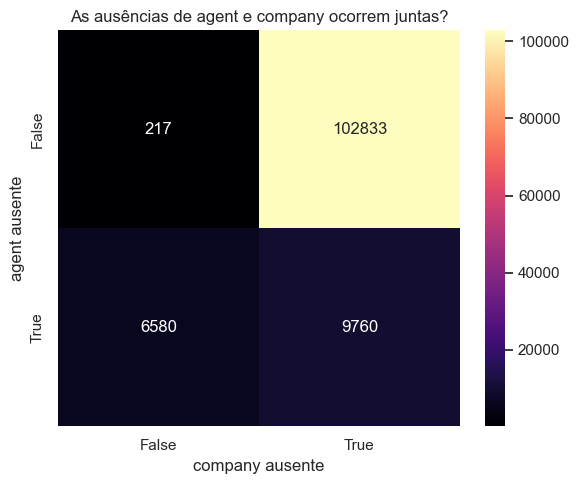

In [11]:
tabela_contingencia = pd.crosstab(
    df["agent"].isna(),
    df["company"].isna(),
    rownames=["agent ausente"],
    colnames=["company ausente"]
)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(tabela_contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title("As ausências de agent e company ocorrem juntas?")
plt.tight_layout()
plt.show()

**Leitura do gráfico:**

O gráfico relaciona os registros `NULL` de `agent` e `company`. `True` indica que o campo está como “não se aplica”, enquanto `False` indica que existe um identificador preenchido.

Observei 102.833 reservas com `agent` preenchido e `company` ausente, além de 9.760 reservas em que os dois campos estavam ausentes. Portanto, essas situações podem acontecer juntas ou separadamente, e `company` aparece preenchida em uma parcela pequena da base.

**Pra discutir:** quantas linhas têm as duas colunas ausentes ao mesmo tempo? Isso muda a hipótese sobre o mecanismo de ausência (MCAR/MAR/MNAR), ou parecem eventos independentes?

*Relembrando:*
- MCAR: a ausência não depende nem do valor ausente nem de outras variáveis observadas.
- MAR: a ausência pode estar relacionada a outras informações observadas no dataset.
- MNAR: a ausência pode depender do próprio valor que não foi registrado.

*Resposta*: Identifiquei 9.760 reservas em que `agent` e `company` estavam ausentes ao mesmo tempo. Entretanto, a documentação original informa que esses `NULL` representam situações em que a informação não se aplica à reserva.

Por isso, não classifiquei essas ausências estruturais como MCAR, MAR ou MNAR. O heatmap foi usado apenas para mostrar que uma reserva pode estar sem agência, sem empresa ou sem as duas informações simultaneamente.

**Nota:** concentrei a comparação em `agent` e `company` porque são os campos com maior número de `NULL` e ambos descrevem vínculos comerciais da reserva.

## 3. Princípio Distribucional

Ainda com os dados originais (sem tratar ausentes ou outliers), vamos calcular as estatísticas descritivas e olhar as distribuições. Esse retrato "antes" é o que vai *orientar as decisões de tratamento* na próxima seção. Por exemplo, se uma variável for muito assimétrica, faz mais sentido imputar com a mediana do que com a média.

In [12]:
VARS_QUANT = [
    "lead_time",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adr",
    "total_of_special_requests"
]

VARS_QUALI = [
    "hotel",
    "meal",
    "market_segment",
    "distribution_channel",
    "deposit_type",
    "customer_type",
    "reserved_room_type",
    "is_repeated_guest"
]

### Tabela descritiva, com assimetria e curtose

desc = df[VARS_QUANT].describe().T
desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
lead_time,104.01,69.00,106.86,0.00,737.00,1.35,1.70
stays_in_weekend_nights,0.93,1.00,1.00,0.00,19.00,1.38,7.17
stays_in_week_nights,2.50,2.00,1.91,0.00,50.00,2.86,24.28
adr,101.83,94.58,50.54,-6.38,5400.00,10.53,1013.19
total_of_special_requests,0.57,0.00,0.79,0.00,5.00,1.35,1.49


**Pra discutir:** olhando a tabela, quais variáveis já parecem assimétricas (`skewness` acima de 1) ou com cauda pesada (`kurtosis` maior que 2 em módulo)? Isso é coerente com o comportamento esperado em reservas de hotéis?

*Resposta*: Todas as variáveis analisadas apresentam assimetria positiva, com maior concentração de reservas nos valores mais baixos e poucos casos com valores muito altos. As caudas mais pesadas aparecem em `stays_in_weekend_nights`, `stays_in_week_nights` e principalmente em `adr`.

Esse resultado é coerente com o domínio: a maior parte das reservas tende a ter poucas noites e valores de diária próximos da faixa usual, enquanto estadias muito longas e diárias muito altas são casos raros. O valor máximo de `adr` merece atenção na etapa de outliers, mas ainda não permite concluir que se trata de um erro.

### Distribuições de dados

Primeiro, observei as distribuições gerais das variáveis quantitativas. Em seguida, comparei as reservas "Not Canceled" (rosa) e "Canceled" (roxo), mantendo essa convenção de cores até a análise bivariada.


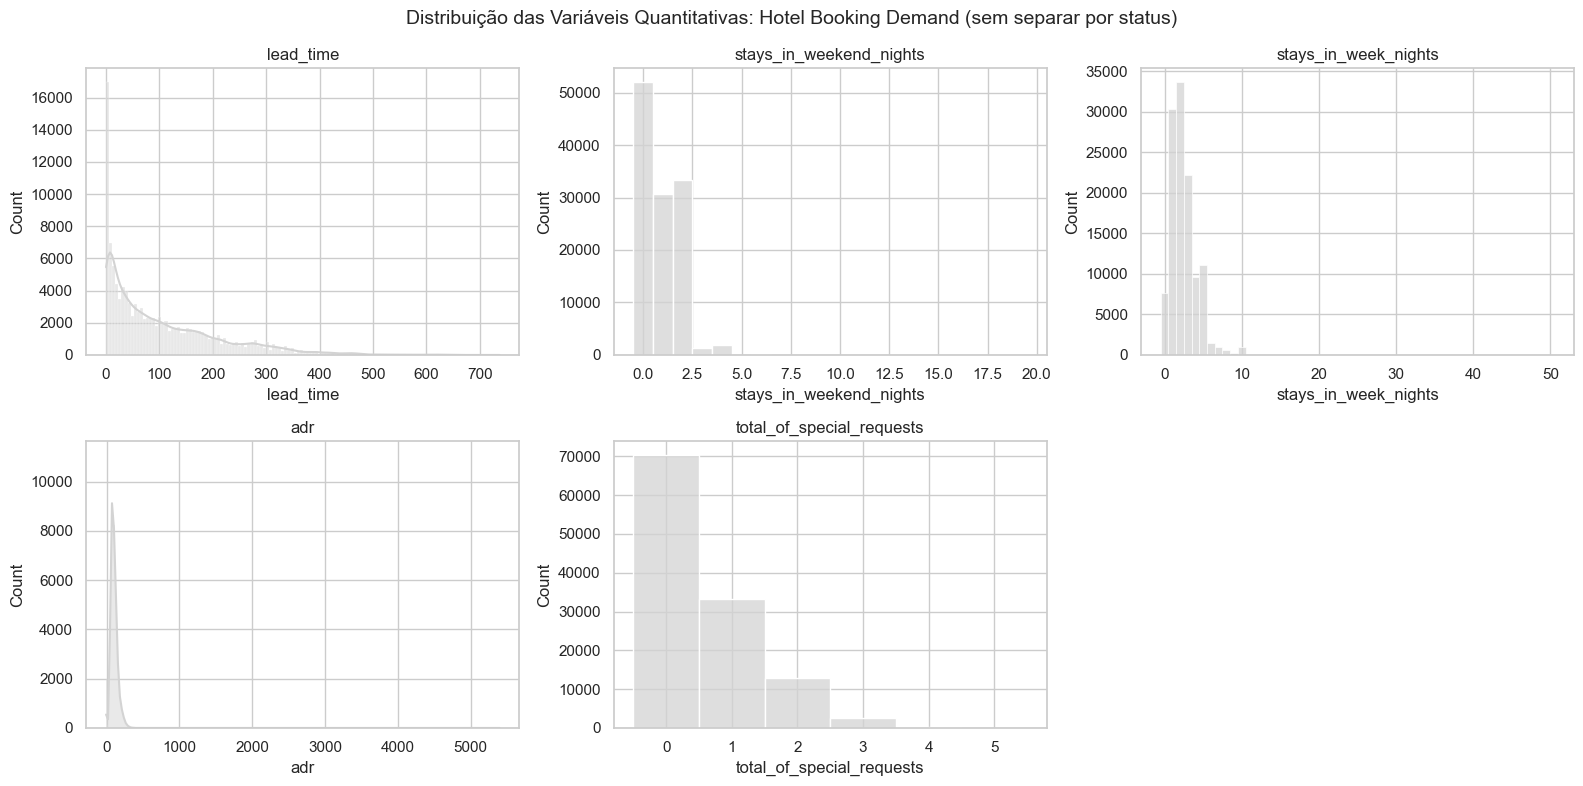

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharey=False)
axes = axes.ravel()

for i, col in enumerate(VARS_QUANT):
    eh_contagem = col in {"stays_in_weekend_nights", "stays_in_week_nights", "total_of_special_requests"}
    sns.histplot(data=df, x=col, kde=not eh_contagem, color=COR_NEUTRA, discrete=eh_contagem, ax=axes[i])
    axes[i].set_title(col)

for ax in axes[len(VARS_QUANT):]:
    ax.axis("off")

fig.suptitle("Distribuição das Variáveis Quantitativas: Hotel Booking Demand (sem separar por status)", fontsize=14)
plt.tight_layout()
plt.show()

**Leitura do gráfico:** Cada painel mostra uma variável considerando todas as reservas. No eixo X estão os valores da variável e, no eixo Y, a quantidade de reservas em cada faixa. Cada painel tem sua própria escala vertical para deixar as barras legíveis; por isso, comparei os formatos, não as alturas entre variáveis. Em `lead_time` e `adr`, a curva ajuda a perceber o formato geral; nas variáveis de contagem, mantive apenas as barras nos valores inteiros.

Observei mais reservas com menor antecedência, poucas noites e poucas solicitações especiais. Em `adr`, a maior parte das diárias ficou em uma faixa mais usual, mas o valor máximo de 5400 alongou bastante o eixo X e deixou essa faixa mais comprimida visualmente. Esse extremo foi investigado na etapa de outliers e mantido no dataset.

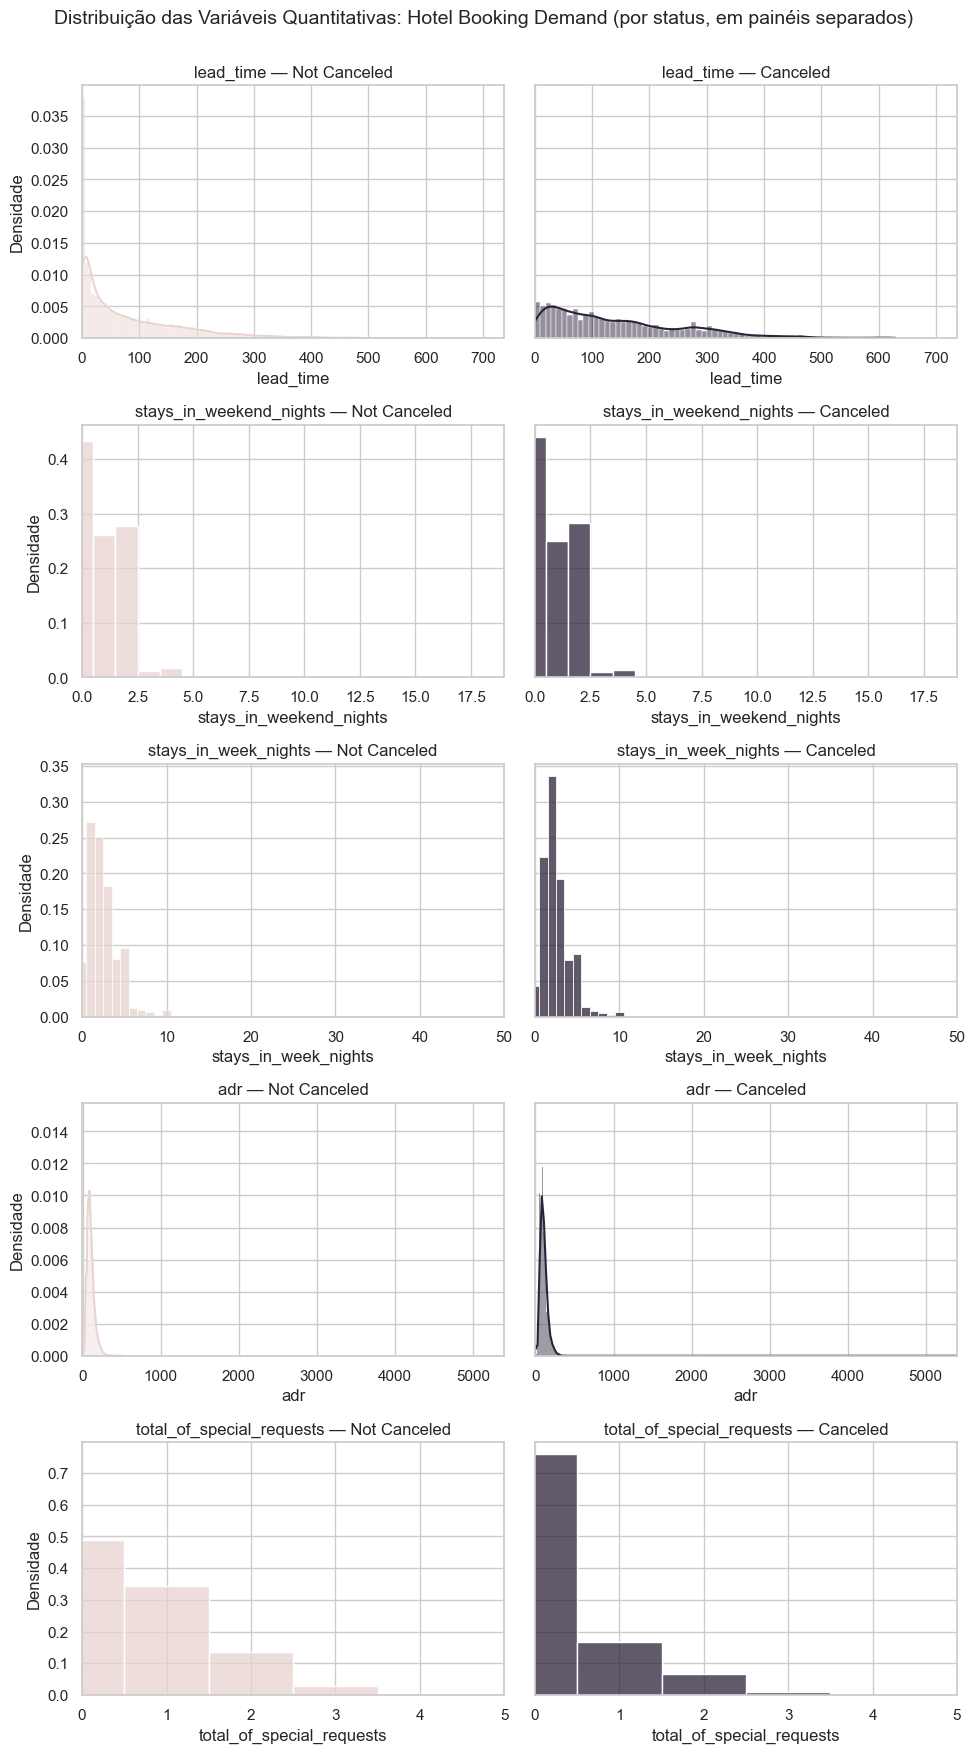

In [14]:
fig, axes = plt.subplots(
    len(VARS_QUANT), 2,
    figsize=(10, 3.5 * len(VARS_QUANT)),
    sharey="row"
)

for i, col in enumerate(VARS_QUANT):
    eh_contagem = col in {"stays_in_weekend_nights", "stays_in_week_nights", "total_of_special_requests"}
    lim = (df[col].min(), df[col].max())

    for j, (classe, cor) in enumerate([
        ("Not Canceled", COR_CONTEXTO),
        ("Canceled", COR_DESTAQUE)
    ]):
        subset = df[df["booking_status"] == classe]
        sns.histplot(
            data=subset,
            x=col,
            kde=not eh_contagem,
            stat="density",
            common_norm=False,
            discrete=eh_contagem,
            color=cor,
            ax=axes[i, j]
        )
        axes[i, j].set_xlim(lim)
        axes[i, j].set_title(f"{col} — {classe}")
        axes[i, j].set_ylabel("Densidade")

fig.suptitle(
    "Distribuição das Variáveis Quantitativas: Hotel Booking Demand "
    "(por status, em painéis separados)",
    fontsize=14,
    y=1.001
)
plt.tight_layout()
plt.show()

**Leitura do gráfico:** cada linha compara a mesma variável entre reservas `Not Canceled` e `Canceled`. O eixo X mostra os valores da variável e o eixo Y mostra a densidade: a área das barras em cada painel soma 1.

Normalizei os painéis porque existem mais reservas não canceladas do que canceladas. Assim, comparei o formato, a concentração e as caudas das distribuições sem confundir essas características com a diferença no tamanho dos grupos.

**Para discutir:** agora que os status estão em painéis separados, alguma variável parece ter formato bem diferente entre reservas "Not Canceled" e "Canceled"?

*Resposta*: Pelos histogramas, `lead_time` parece apresentar a diferença mais perceptível entre os grupos. As reservas `Canceled` aparecem mais distribuídas em valores altos de antecedência, enquanto as reservas `Not Canceled` se concentram mais nos valores menores.

Em `total_of_special_requests`, as reservas canceladas parecem estar mais concentradas em zero solicitações especiais.

Já as variáveis relacionadas à quantidade de noites apresentam formatos mais parecidos entre os grupos. Em `adr`, a comparação fica menos detalhada porque valores extremos alongam bastante a escala do gráfico.

#### Testes de Aderência

Verifiquei se `lead_time` se aproxima de uma distribuição normal. Escolhi essa variável porque representa a antecedência da reserva, é numérica e já apresentou assimetria na tabela descritiva. Apliquei o Shapiro-Wilk em uma amostra fixa de 5.000 reservas e usei o QQ-Plot como apoio visual.

Shapiro-Wilk — lead_time (amostra de 5000): estatística=0.8581, p-valor=2.821e-55
Rejeita H0 (normalidade)? Sim (alpha = 0.05)


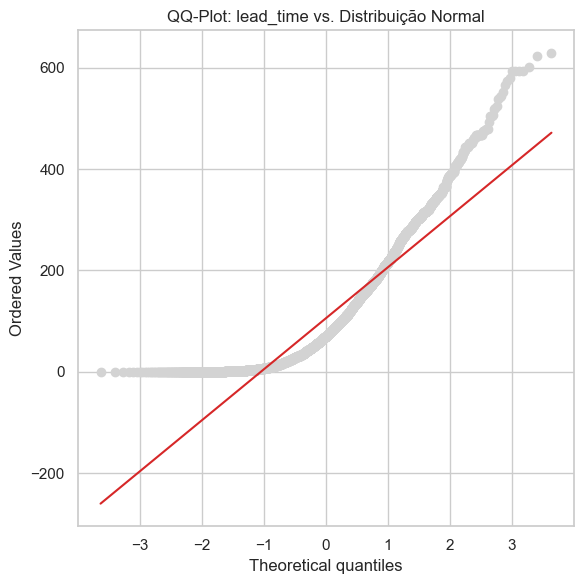

In [15]:
TAMANHO_AMOSTRA_NORMALIDADE = 5000
amostra_normalidade = df.sample(n=TAMANHO_AMOSTRA_NORMALIDADE, random_state=42)
lead_time_amostra = amostra_normalidade["lead_time"].dropna()

stat_sw, p_valor_sw = stats.shapiro(lead_time_amostra)
print(f"Shapiro-Wilk — lead_time (amostra de {TAMANHO_AMOSTRA_NORMALIDADE}): estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print("Rejeita H0 (normalidade)?", "Sim" if p_valor_sw < 0.05 else "Não", "(alpha = 0.05)")

fig, ax = plt.subplots(figsize=(6, 6))
stats.probplot(lead_time_amostra, dist="norm", plot=ax)
ax.get_lines()[0].set_markerfacecolor(COR_NEUTRA)
ax.get_lines()[0].set_markeredgecolor(COR_NEUTRA)
ax.get_lines()[1].set_color(COR_ALERTA)
ax.set_title("QQ-Plot: lead_time vs. Distribuição Normal")
plt.tight_layout()
plt.show()

**Leitura do gráfico:** no QQ-Plot, o eixo X mostra posições esperadas em uma distribuição normal, enquanto o eixo Y mostra os valores reais de `lead_time` em dias. Por isso, os eixos possuem escalas diferentes. A reta vermelha representa o padrão esperado em uma distribuição normal.

Observei que os pontos formam uma curva e se afastam da reta, principalmente nos valores mais altos. Isso mostra que `lead_time` não segue uma distribuição normal e possui assimetria à direita. O p-valor muito pequeno do Shapiro-Wilk confirma essa observação.

In [16]:
resultados_shapiro = []
for col in VARS_QUANT:
    stat, p = stats.shapiro(amostra_normalidade[col].dropna())
    resultados_shapiro.append({"variavel": col, "estatistica": round(stat, 4),
                                "p_valor": f"{p:.3e}", "rejeita_normalidade": p < 0.05})

pd.DataFrame(resultados_shapiro).set_index("variavel")

,estatistica,p_valor,rejeita_normalidade
variavel,,,
lead_time,0.8581,2.821e-55,True
stays_in_weekend_nights,0.7886,1.208e-62,True
stays_in_week_nights,0.8239,3.299e-59,True
adr,0.9406,7.410e-41,True
total_of_special_requests,0.7101,8.369e-69,True


**Leitura da tabela:** as cinco variáveis quantitativas rejeitam normalidade na amostra de 5.000 reservas. As variáveis de noites e solicitações especiais são contagens discretas, portanto não é esperado que sigam perfeitamente uma distribuição normal.

**ECDF — outra forma de ver a distribuição:** a curva mostra a proporção acumulada de reservas até cada valor de `lead_time`. Ela permite comparar os dois status sem depender das barras do histograma.

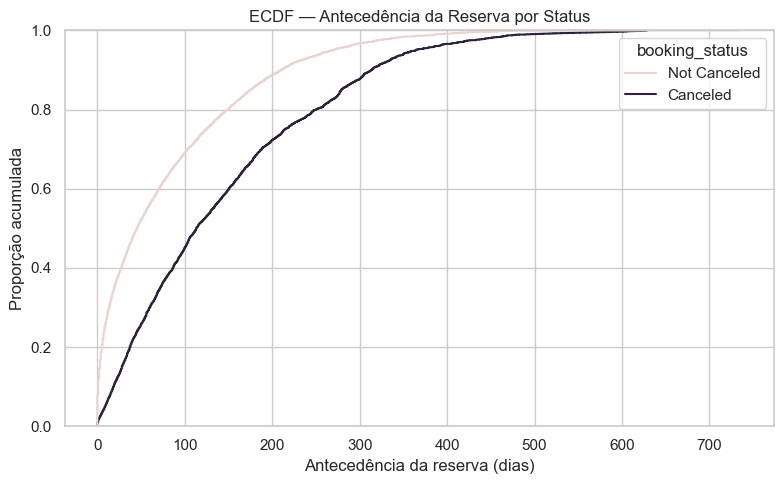

In [17]:
plt.figure(figsize=(8, 5))
sns.ecdfplot(data=df, x="lead_time", hue="booking_status",
             palette={"Not Canceled": COR_CONTEXTO, "Canceled": COR_DESTAQUE})
plt.title("ECDF — Antecedência da Reserva por Status")
plt.xlabel("Antecedência da reserva (dias)")
plt.ylabel("Proporção acumulada")
plt.tight_layout()
plt.show()

**Leitura do gráfico:** o eixo X mostra a antecedência da reserva em dias e o eixo Y mostra a proporção acumulada de reservas.

Observei que a curva de `Not Canceled` sobe mais rapidamente nos menores valores de `lead_time`, enquanto a de `Canceled` avança mais para a direita. Isso indica que reservas canceladas tendem a aparecer com mais frequência em antecedentes maiores.

### Métricas de Tendência Central

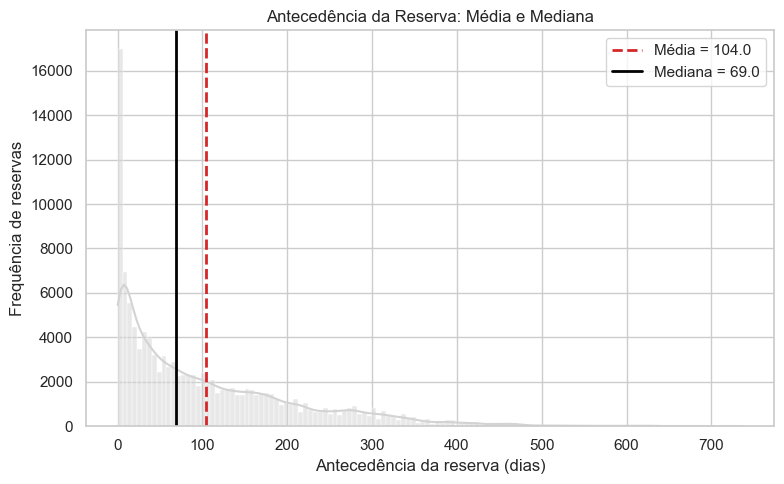

In [18]:
media_lead_time = df["lead_time"].mean()
mediana_lead_time = df["lead_time"].median()

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="lead_time", kde=True, color=COR_NEUTRA)
plt.axvline(media_lead_time, color=COR_ALERTA, linestyle="--", linewidth=2, label=f"Média = {media_lead_time:.1f}")
plt.axvline(mediana_lead_time, color="black", linestyle="-", linewidth=2, label=f"Mediana = {mediana_lead_time:.1f}")
plt.title("Antecedência da Reserva: Média e Mediana")
plt.xlabel("Antecedência da reserva (dias)")
plt.ylabel("Frequência de reservas")
plt.legend()
plt.tight_layout()
plt.show()

**Leitura do gráfico:** o histograma mostra a frequência de reservas em cada faixa de antecedência. A linha vermelha tracejada representa a média e a linha preta representa a mediana. Quando média e mediana ficam afastadas, isso ajuda a identificar o efeito de valores mais altos ou mais baixos sobre a distribuição.

Observei que a média de `lead_time` está à direita da mediana. Isso mostra que alguns valores altos de antecedência puxam a média para cima, enquanto a maior concentração de reservas está em valores menores. Essa observação confirma a assimetria à direita vista no histograma e no QQ-Plot.

### Dispersão

Comparei a variabilidade das cinco variáveis quantitativas em uma tabela e em boxplots e violin plots separados pelo status da reserva.

,var,std,IQR
lead_time,11419.72,106.86,142.00
stays_in_weekend_nights,1.00,1.00,2.00
stays_in_week_nights,3.64,1.91,2.00
adr,2553.87,50.54,56.71
total_of_special_requests,0.63,0.79,1.00


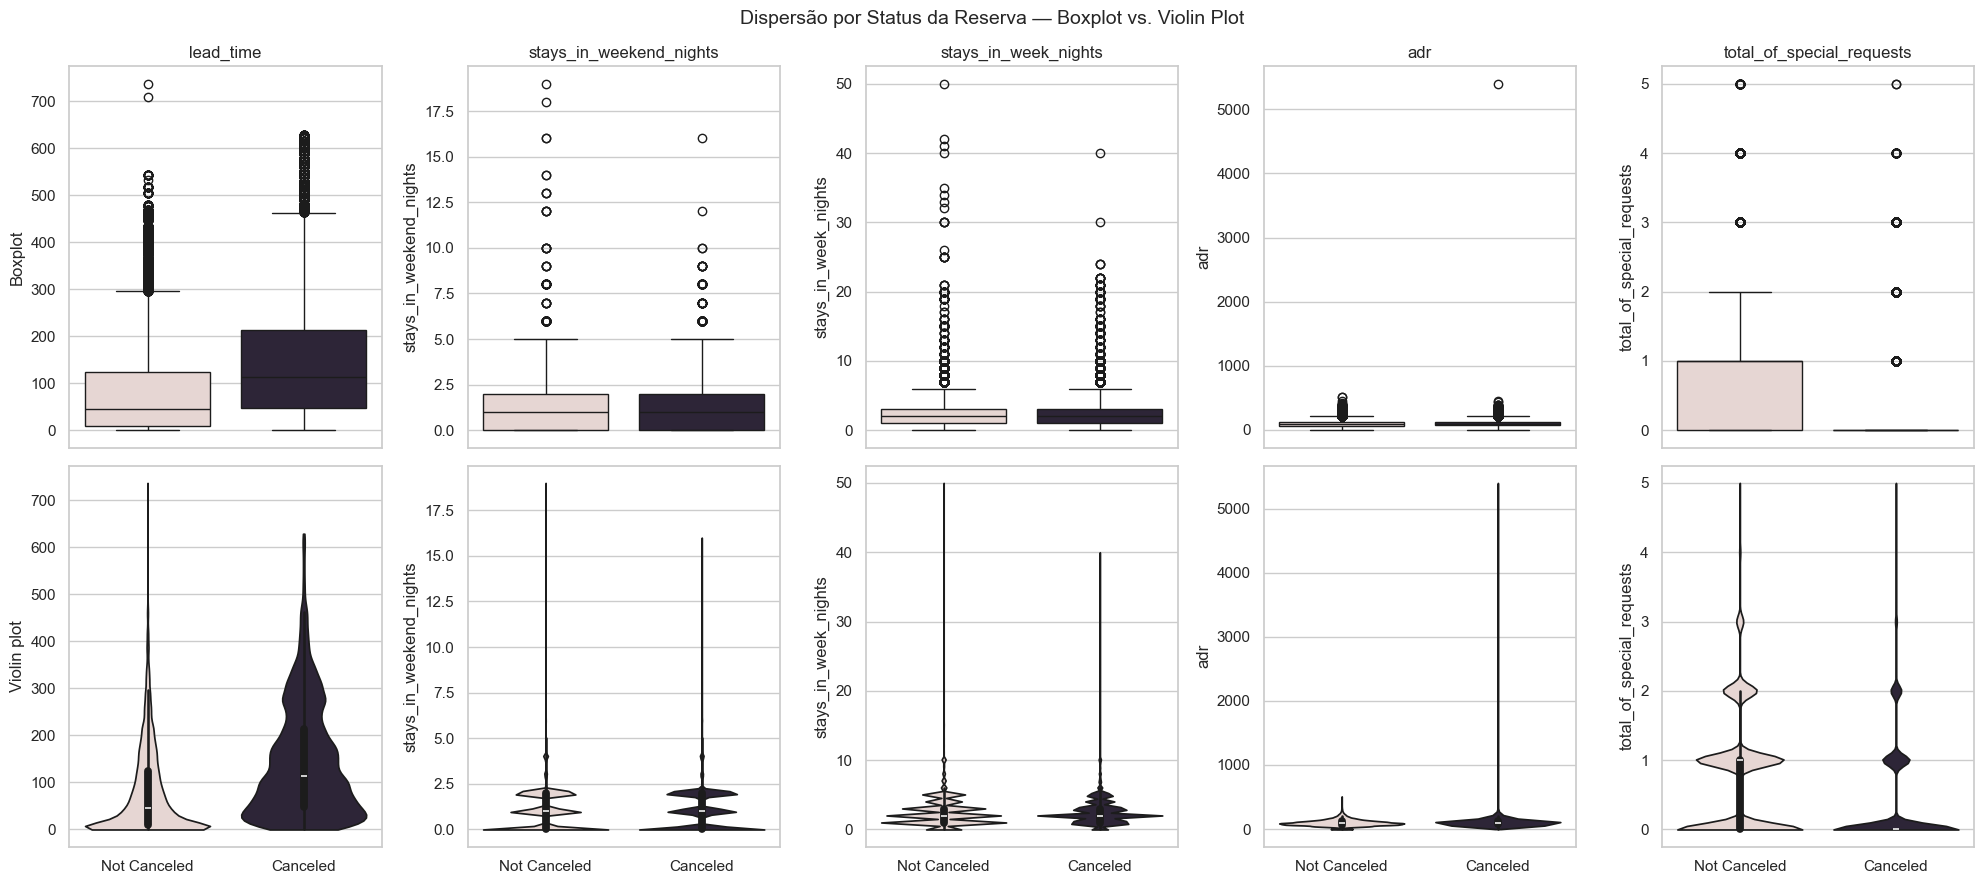

In [19]:
dispersao = df[VARS_QUANT].agg(["var", "std"]).T
dispersao["IQR"] = df[VARS_QUANT].quantile(0.75) - df[VARS_QUANT].quantile(0.25)
display(dispersao.round(2))

palette_status = {"Not Canceled": COR_CONTEXTO, "Canceled": COR_DESTAQUE}

fig, axes = plt.subplots(2, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 9), sharex="col")

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(
        data=df, x="booking_status", y=col, hue="booking_status",
        palette=palette_status, legend=False, ax=axes[0, i]
    )
    axes[0, i].set_title(col)
    axes[0, i].set_xlabel("")

    sns.violinplot(
        data=df, x="booking_status", y=col, hue="booking_status",
        palette=palette_status, legend=False, cut=0, ax=axes[1, i]
    )
    axes[1, i].set_xlabel("")

axes[0, 0].set_ylabel("Boxplot")
axes[1, 0].set_ylabel("Violin plot")
fig.suptitle("Dispersão por Status da Reserva — Boxplot vs. Violin Plot", fontsize=14)
plt.tight_layout()
plt.show()

**Leitura do resultado e do gráfico:** a tabela apresenta variância, desvio-padrão e IQR das cinco variáveis. Nos gráficos, o boxplot resume mediana, quartis e pontos extremos, enquanto a largura do violin plot mostra onde os valores estão mais concentrados.

Observei a diferença mais clara em `lead_time`: as reservas `Canceled` apresentam valores centrais e dispersão maiores. As variáveis de noites ficaram mais sobrepostas, e as reservas canceladas se concentraram em zero solicitação especial. Em `adr`, o valor extremo alongou a escala e dificultou a comparação da faixa principal.

**Para discutir:** alguma variável mostra uma caixa (IQR) nitidamente mais alta ou mais baixa entre reservas `Not Canceled` e `Canceled`? Isso já é um indício visual, antes da análise bivariada formal, de que a variável pode ajudar a diferenciar os grupos.

*Resposta*: Observei a diferença mais clara em `lead_time`: o IQR das reservas `Canceled` é mais alto do que o das `Not Canceled`. Em `total_of_special_requests`, as reservas canceladas se concentram em zero, enquanto as não canceladas se distribuem por mais valores. Essas variáveis podem ajudar a diferenciar visualmente os grupos.

## 4. Tratamento de Dados Ausentes e Outliers

Depois de observar o retrato estatístico "antes" (Seção 3), decidi como tratar os dados ausentes e os outliers conforme o significado de cada feature, sem remover registros automaticamente. Em seguida, repeti a estatística descritiva para verificar o efeito dessas decisões.

### Detecção de Outliers por IQR

A regra clássica marca como outlier qualquer ponto fora de `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`.

In [20]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

resumo_outliers = {}
for col in VARS_QUANT:
    lim_inf, lim_sup = limites_iqr(df[col])
    n_outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    resumo_outliers[col] = {
        "limite_inferior": round(lim_inf, 2),
        "limite_superior": round(lim_sup, 2),
        "n_outliers": n_outliers,
    }

tabela_outliers = pd.DataFrame(resumo_outliers).T
tabela_outliers["n_outliers"] = tabela_outliers["n_outliers"].astype(int)
tabela_outliers

,limite_inferior,limite_superior,n_outliers
lead_time,-195.00,373.00,3005
stays_in_weekend_nights,-3.00,5.00,265
stays_in_week_nights,-2.00,6.00,3354
adr,-15.77,211.06,3793
total_of_special_requests,-1.50,2.50,2877


**Leitura do resultado:** a tabela mostra os limites inferior e superior da regra do IQR e a quantidade de candidatos a outlier em cada variável quantitativa.

Observei que `adr` apresentou a maior quantidade, com 3.793 casos, enquanto `stays_in_weekend_nights` apresentou a menor, com 265. As cinco variáveis possuem valores fora dos respectivos limites.

### Visualizando os Outliers


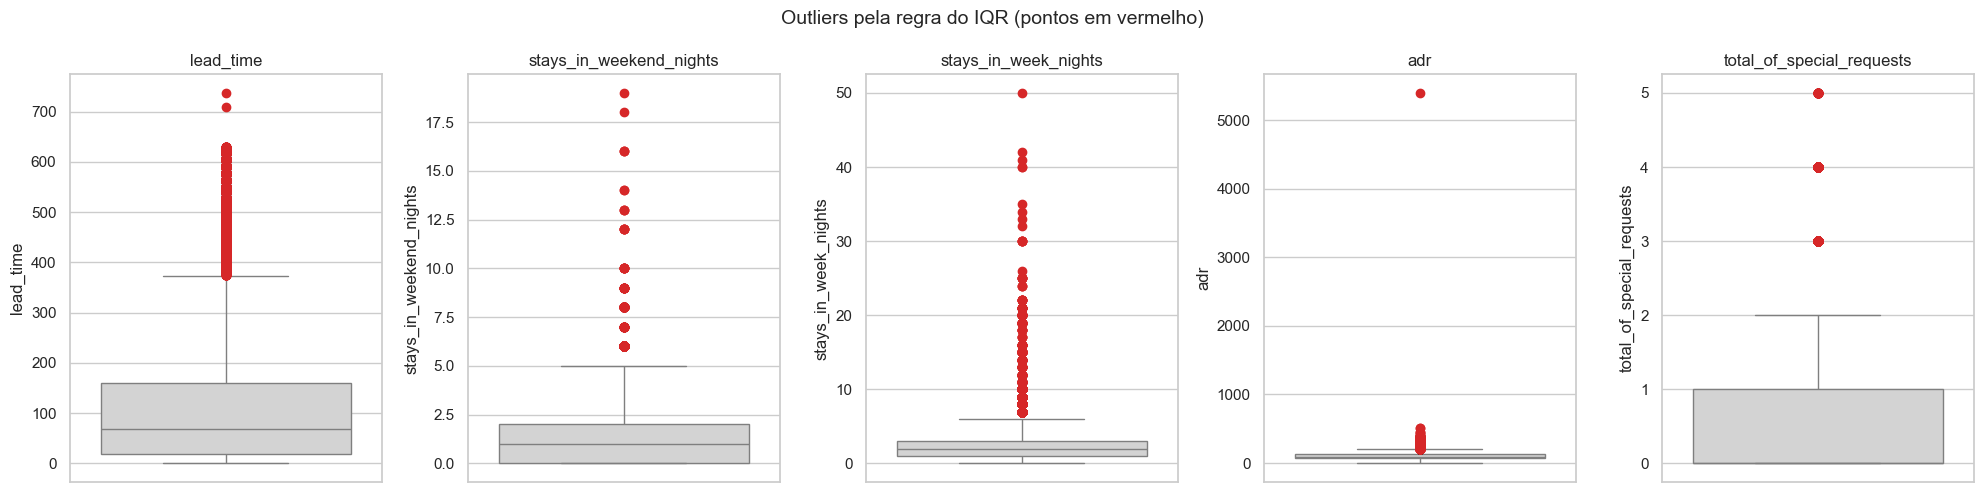

In [21]:
fig, axes = plt.subplots(1, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 5))

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, y=col, color=COR_NEUTRA,
                flierprops=dict(markerfacecolor=COR_ALERTA, markeredgecolor=COR_ALERTA, marker="o"),
                ax=axes[i])
    axes[i].set_title(col)

fig.suptitle("Outliers pela regra do IQR (pontos em vermelho)", fontsize=14)
plt.tight_layout()
plt.show()

**Leitura do gráfico:** os boxplots mostram a faixa central, a mediana e, em vermelho, os candidatos a outlier identificados pela regra do IQR.

Observei pontos fora dos limites nas cinco variáveis. Em `adr`, os valores altos se destacaram por causa da escala ampla. Em `lead_time`, também apareceram reservas com antecedência muito superior à maior concentração dos dados.

**Pra discutir:** o slide 26 da aula 9 classifica outliers em três tipos, cada um com um tratamento recomendado:

| Tipo | Cenário | O que fazer? |
|---|---|---|
| Estatístico | Legítimo | Manter / Transformar |
| De domínio | Viola regra de negócio ou condições físicas | Investigar! |
| Erros de dados | Falhas | Corrigir se possível / Remover como última opção |

Olhando os outliers encontrados nas variáveis de reservas: eles parecem valores raros, mas possíveis, ou parecem violar alguma regra de negócio?

*Resposta*: Valores altos de antecedência, de noites e de ADR podem ser raros, mas possíveis em reservas de hotel. Como os gráficos não comprovam erro de registro, não removi esses candidatos automaticamente. O ADR negativo, identificado na Seção 3, foi analisado separadamente no bloco seguinte.


Além dos candidatos identificados pela regra do IQR, na Seção 3 a tabela descritiva mostrou um valor mínimo negativo em `adr`. Como uma diária média negativa é incomum no contexto de reservas de hotel, verifiquei essa reserva antes de decidir se alguma alteração seria necessária.


In [22]:
cols_adr_negativo = [
    "hotel",
    "booking_status",
    "lead_time",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adults",
    "meal",
    "market_segment",
    "is_repeated_guest",
    "reserved_room_type",
    "assigned_room_type",
    "adr"
]

print("Mínimo e máximo de ADR por hotel:")
display(df.groupby("hotel")["adr"].agg(["min", "max"]))

print("Reserva com ADR negativo:")
display(df.loc[df["adr"] < 0, cols_adr_negativo])

Mínimo e máximo de ADR por hotel:


,min,max
hotel,,
City Hotel,0.00,5400.0
Resort Hotel,-6.38,508.0


Reserva com ADR negativo:


,hotel,booking_status,lead_time,stays_in_weekend_nights,stays_in_week_nights,adults,meal,market_segment,is_repeated_guest,reserved_room_type,assigned_room_type,adr
14969,Resort Hotel,Not Canceled,195,4,6,2,BB,Groups,1,A,H,-6.38


**Leitura do resultado:** a tabela confirmou `adr` mínimo de `-6,38` no Resort Hotel e máximo de `5400` no City Hotel. Esses mesmos extremos aparecem nas tabelas descritivas publicadas no [artigo original do dataset](https://pmc.ncbi.nlm.nih.gov/articles/PMC6297060/).

Como a fonte preservou esses valores e não explicou a causa operacional do ADR negativo, documentei o caso sem inventar uma justificativa e mantive o registro na base.

### Decidindo o Tratamento dos Dados Ausentes

Tratei os dados ausentes sem excluir reservas. Calculei a mediana de `children`, que resultou em zero, e usei esse valor nas quatro ausências. Em `country`, usei `Unknown`.

Em `agent` e `company`, usei `No Agent` e `No Company`, pois a documentação original define esses `NULL` como situações em que a informação não se aplica à reserva.

In [23]:
df_antes = df.copy()
df_tratado = df.copy()

mediana_children = int(df_tratado["children"].median())
df_tratado["children"] = df_tratado["children"].fillna(mediana_children).astype(int)
df_tratado["country"] = df_tratado["country"].fillna("Unknown")
df_tratado["agent"] = df_tratado["agent"].astype("object").fillna("No Agent")
df_tratado["company"] = df_tratado["company"].astype("object").fillna("No Company")

print(f"Mediana usada em children: {mediana_children}")
print(f"Linhas antes: {df_antes.shape[0]} | Linhas depois: {df_tratado.shape[0]}")
print("Ausentes restantes:", int(df_tratado.isna().sum().sum()))

Mediana usada em children: 0
Linhas antes: 119390 | Linhas depois: 119390


Ausentes restantes: 0


**Leitura do resultado:** a saída mostrou que a mediana usada em `children` foi zero. A base permaneceu com 119.390 linhas e terminou sem valores ausentes. Portanto, tratei os quatro campos sem excluir reservas.

### Decidindo o Tratamento dos Outliers

Não removi os outliers automaticamente. Valores extremos podem representar reservas legítimas, e o dataset não oferece evidência suficiente para classificá-los como erros de coleta. Mantive os valores originais e usei a transformação logarítmica apenas como demonstração em `lead_time`, que é não negativa e assimétrica.

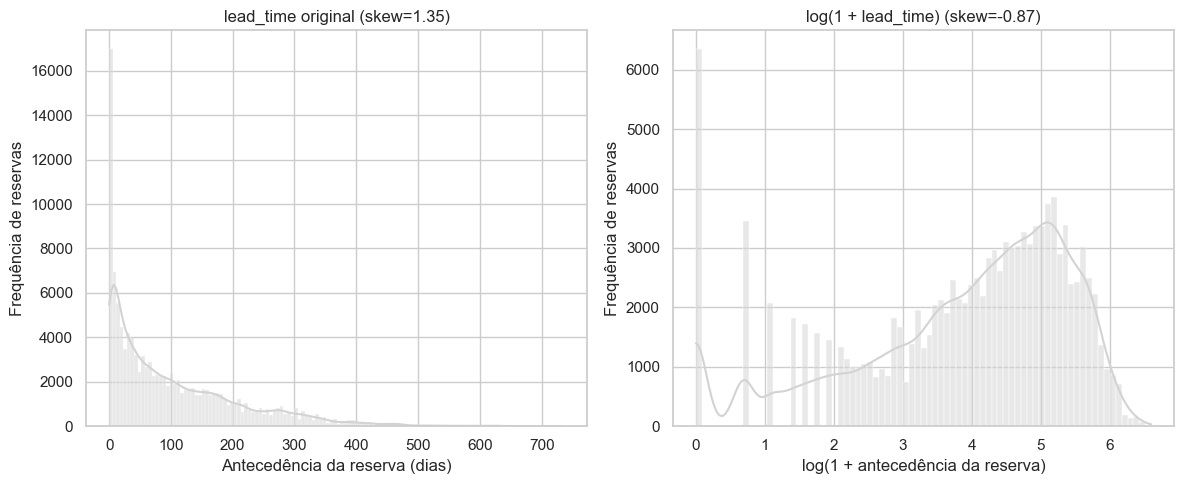

In [24]:
df_tratado["lead_time_log"] = np.log1p(df_tratado["lead_time"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(data=df_tratado, x="lead_time", kde=True, color=COR_NEUTRA, ax=axes[0])
axes[0].set_title(f"lead_time original (skew={df_tratado['lead_time'].skew():.2f})")
axes[0].set_xlabel("Antecedência da reserva (dias)")
axes[0].set_ylabel("Frequência de reservas")

sns.histplot(data=df_tratado, x="lead_time_log", kde=True, color=COR_NEUTRA, ax=axes[1])
axes[1].set_title(f"log(1 + lead_time) (skew={df_tratado['lead_time_log'].skew():.2f})")
axes[1].set_xlabel("log(1 + antecedência da reserva)")
axes[1].set_ylabel("Frequência de reservas")

plt.tight_layout()
plt.show()

**Leitura do gráfico:** comparei a distribuição original de `lead_time` com a versão `log(1 + lead_time)`.

A assimetria passou de `1,35` para `-0,87`. Em módulo, ela diminuiu, mas também mudou de positiva para negativa. Portanto, o log comprimiu a cauda direita, porém não tornou a distribuição normal. Mantive `lead_time` original nas análises seguintes.

**Pra discutir:** a transformação logarítmica reduziu visivelmente a assimetria de `lead_time`? Mantivemos `lead_time_log` apenas como demonstração e continuaremos usando a variável original nas próximas seções.

*Resposta*: Sim. Observei uma redução da assimetria em módulo, mas ela passou a ser negativa. Por isso, interpretei o log apenas como uma demonstração de compressão dos valores altos e mantive a variável original.

**Nota para quando vocês replicarem no dataset de vocês:** nem todo outlier deve ser removido. Antes de decidir, classifiquem: é um valor estatisticamente raro mas plausível (manter/transformar), viola alguma regra física ou de negócio (investigar antes de decidir), ou é claramente um erro de digitação/coleta (corrigir ou remover)?

## 5. Estatística Descritiva pt 2

Fechando o ciclo iterativo: tratamos os ausentes e decidimos manter os outliers. Agora rodamos a mesma bateria de estatísticas da Seção 3 para comparar diretamente com o "antes".

In [25]:
desc_depois = df_tratado[VARS_QUANT].describe().T
desc_depois["skewness"] = df_tratado[VARS_QUANT].skew()
desc_depois["kurtosis"] = df_tratado[VARS_QUANT].kurtosis()

(
    desc_depois[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="Blues", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
lead_time,104.01,69.00,106.86,0.00,737.00,1.35,1.70
stays_in_weekend_nights,0.93,1.00,1.00,0.00,19.00,1.38,7.17
stays_in_week_nights,2.50,2.00,1.91,0.00,50.00,2.86,24.28
adr,101.83,94.58,50.54,-6.38,5400.00,10.53,1013.19
total_of_special_requests,0.57,0.00,0.79,0.00,5.00,1.35,1.49


**Leitura do resultado:** observei que as medidas descritivas das cinco variáveis quantitativas permaneceram iguais às da Seção 3. Isso ocorreu porque o tratamento foi aplicado apenas às features com dados ausentes, sem modificar essas variáveis nem remover reservas.


### Comparando "antes" x "depois"


In [26]:
comparacao = pd.DataFrame({
    "skewness_antes": desc["skewness"],
    "skewness_depois": desc_depois["skewness"],
    "kurtosis_antes": desc["kurtosis"],
    "kurtosis_depois": desc_depois["kurtosis"],
})
comparacao["delta_skewness"] = (comparacao["skewness_depois"] - comparacao["skewness_antes"]).round(3)
comparacao["delta_kurtosis"] = (comparacao["kurtosis_depois"] - comparacao["kurtosis_antes"]).round(3)
comparacao.round(3)

,skewness_antes,skewness_depois,kurtosis_antes,kurtosis_depois,delta_skewness,delta_kurtosis
lead_time,1.347,1.347,1.696,1.696,0.0,0.0
stays_in_weekend_nights,1.380,1.380,7.174,7.174,0.0,0.0
stays_in_week_nights,2.862,2.862,24.285,24.285,0.0,0.0
adr,10.530,10.530,1013.190,1013.190,0.0,0.0
total_of_special_requests,1.349,1.349,1.493,1.493,0.0,0.0


**Leitura do resultado:** na tabela de comparação, identifiquei `0.0` em todos os deltas de assimetria e curtose. Assim, confirmei que as características das cinco variáveis quantitativas foram preservadas após o tratamento.


**Pra discutir:** os valores mudaram muito? Como o tratamento alterou apenas features que não fazem parte de `VARS_QUANT` e manteve os outliers, é esperado que essa tabela apresente pouca ou nenhuma mudança.

**Testes de aderência depois do tratamento**

Repeti o Shapiro-Wilk para as cinco variáveis quantitativas, usando os mesmos índices da amostra fixa de 5.000 reservas. Como não houve alteração nessas cinco variáveis, verifiquei se o tratamento conservador de ausências manteve essa avaliação.

In [27]:
resultados_shapiro_depois = []
for col in VARS_QUANT:
    amostra_depois = df_tratado.loc[amostra_normalidade.index, col].dropna()
    stat_depois, p_depois = stats.shapiro(amostra_depois)
    resultados_shapiro_depois.append({
        "variavel": col,
        "estatistica_depois": round(stat_depois, 4),
        "p_valor_depois": f"{p_depois:.3e}",
        "rejeita_normalidade_depois": p_depois < 0.05,
    })

pd.DataFrame(resultados_shapiro_depois).set_index("variavel")

,estatistica_depois,p_valor_depois,rejeita_normalidade_depois
variavel,,,
lead_time,0.8581,2.821e-55,True
stays_in_weekend_nights,0.7886,1.208e-62,True
stays_in_week_nights,0.8239,3.299e-59,True
adr,0.9406,7.410e-41,True
total_of_special_requests,0.7101,8.369e-69,True


**Leitura do resultado:** observei que as cinco variáveis continuaram rejeitando normalidade na mesma amostra de 5.000 reservas. Esse resultado era esperado, pois nenhuma variável quantitativa foi alterada no tratamento.


**Visualizando antes x depois, lado a lado**

Sobrepus a distribuição de `lead_time`, comparando a versão original (`df_antes`) com a tratada (`df_tratado`).

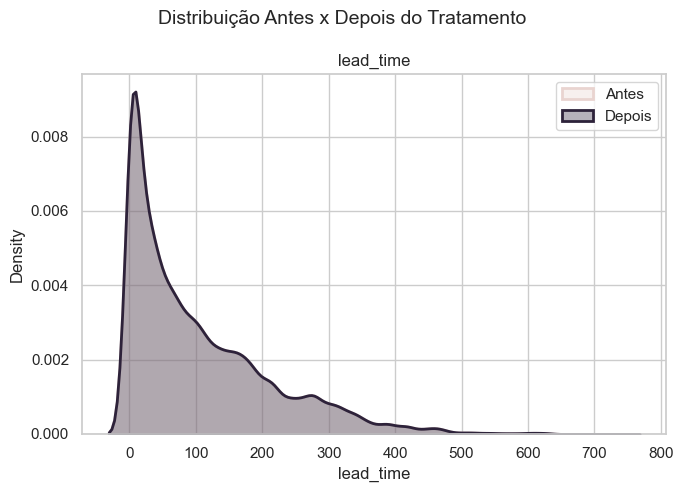

In [28]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.kdeplot(df_antes["lead_time"], color=COR_CONTEXTO, fill=True, alpha=0.35, linewidth=2, label="Antes", ax=ax)
sns.kdeplot(df_tratado["lead_time"], color=COR_DESTAQUE, fill=True, alpha=0.35, linewidth=2, label="Depois", ax=ax)
ax.set_title("lead_time")
ax.legend()

fig.suptitle("Distribuição Antes x Depois do Tratamento", fontsize=14)
plt.tight_layout()
plt.show()

**Leitura do gráfico:** observei que as curvas de `lead_time` se sobrepõem. Isso confirma visualmente o resultado das tabelas: como `lead_time` não foi modificada e nenhuma reserva foi removida, sua distribuição permaneceu a mesma.


**Pra discutir:** as curvas “antes” e “depois” praticamente se sobrepõem? Isso é o esperado aqui, pois `lead_time` não foi alterada e os outliers foram mantidos.

Em datasets nos quais a estratégia de tratamento modifica a variável analisada, essa comparação permite verificar se o efeito esperado realmente ocorreu, em vez de assumir isso sem evidência.

## 6. Princípio Relacional

### Análise de Variáveis Qualitativas

Nesta etapa, avaliei as frequências e o desbalanceamento das variáveis qualitativas.

#### Frequências absolutas e relativas

In [29]:
for col in VARS_QUALI:
    freq_abs = df_tratado[col].value_counts()
    freq_rel = df_tratado[col].value_counts(normalize=True).round(3)
    print(f"\\n--- {col} ---")
    print(pd.concat([freq_abs.rename("absoluta"), freq_rel.rename("relativa")], axis=1))

\n--- hotel ---
              absoluta  relativa
hotel                           
City Hotel       79330     0.664
Resort Hotel     40060     0.336
\n--- meal ---
           absoluta  relativa
meal                         
BB            92310     0.773
HB            14463     0.121
SC            10650     0.089
Undefined      1169     0.010
FB              798     0.007
\n--- market_segment ---
                absoluta  relativa
market_segment                    
Online TA          56477     0.473
Offline TA/TO      24219     0.203
Groups             19811     0.166
Direct             12606     0.106
Corporate           5295     0.044
Complementary        743     0.006
Aviation             237     0.002
Undefined              2     0.000
\n--- distribution_channel ---
                      absoluta  relativa
distribution_channel                    
TA/TO                    97870     0.820
Direct                   14645     0.123
Corporate                 6677     0.056
GDS             

**Leitura do resultado:** ao observar as frequências, identifiquei categorias predominantes em várias variáveis, como `TA/TO` em `distribution_channel`, `No Deposit` em `deposit_type` e `Transient` em `customer_type`.

O maior desbalanceamento apareceu em `is_repeated_guest`: a categoria `0` representa 96,8% das reservas, enquanto a categoria `1` representa 3,2%. Também identifiquei categorias muito pouco frequentes, que exigirão cuidado nos cruzamentos posteriores, pois comparar apenas quantidades absolutas poderia ser enganoso.


#### Visualizando as frequências

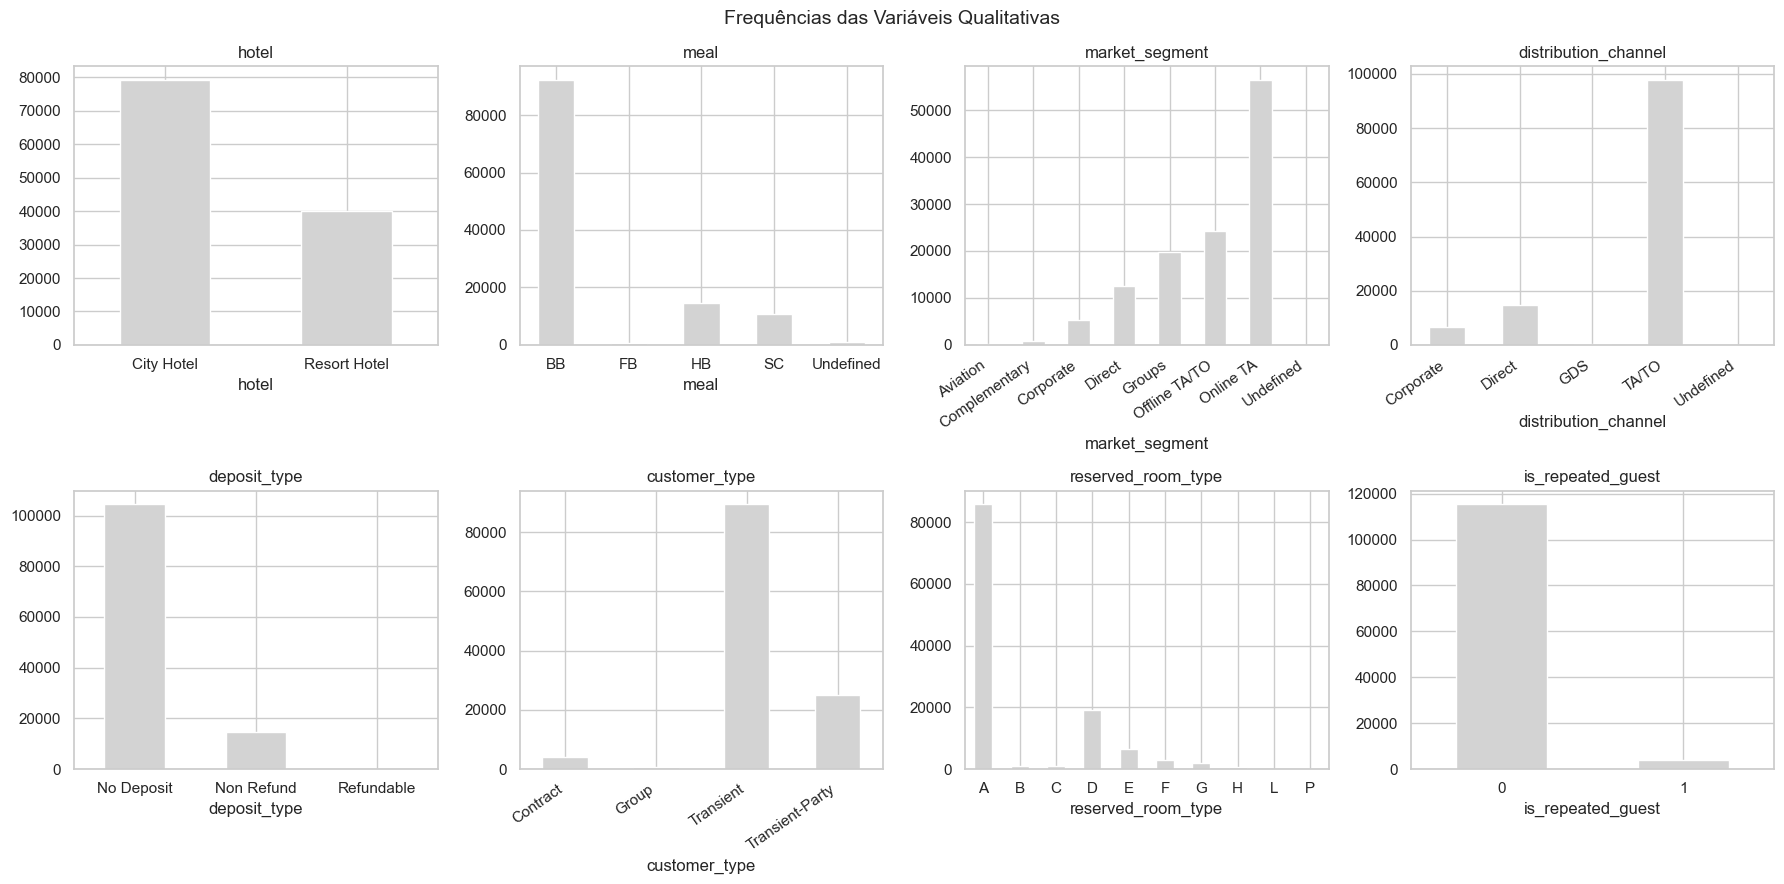

In [30]:
fig, axes = plt.subplots(2, 4, figsize=(18, 9), sharey=False)
axes = axes.ravel()

cols_rotacao = {"market_segment", "distribution_channel", "customer_type"}

for i, col in enumerate(VARS_QUALI):
    df_tratado[col].value_counts().sort_index().plot(
        kind="bar", color=COR_NEUTRA, ax=axes[i]
    )
    axes[i].set_title(col)

    rotacao = 35 if col in cols_rotacao else 0
    alinhamento = "right" if rotacao else "center"
    axes[i].tick_params(axis="x", rotation=rotacao)
    for rotulo in axes[i].get_xticklabels():
        rotulo.set_horizontalalignment(alinhamento)

fig.suptitle("Frequências das Variáveis Qualitativas", fontsize=14)
plt.tight_layout()
plt.show()

**Leitura do gráfico:** cada painel mostra a frequência absoluta das categorias de uma variável qualitativa. O eixo X identifica as categorias e o eixo Y mostra a quantidade de reservas. Mantive uma escala vertical própria em cada painel e girei os rótulos mais longos para melhorar a leitura.

Observei categorias predominantes, especialmente `TA/TO` em `distribution_channel`, `No Deposit` em `deposit_type` e `0` em `is_repeated_guest`. Em `hotel`, a diferença entre as categorias foi menor; em `reserved_room_type`, os tipos de quarto apresentaram frequências bastante distintas.

**Pra discutir:** alguma variável qualitativa está bem desbalanceada (uma categoria dominando quase todas as observações)? Isso pode impactar como vamos interpretar cruzamentos com essa variável mais na frente na análise bivariada.

*Resposta*: Sim. Observei categorias claramente dominantes em várias variáveis. Os exemplos mais evidentes foram `is_repeated_guest`, com predominância da categoria `0`, `deposit_type`, com maior concentração em `No Deposit`, e `distribution_channel`, em que `TA/TO` apareceu com muito mais reservas que os demais canais.

Esse desbalanceamento exige cuidado nos cruzamentos posteriores, porque categorias pouco frequentes podem parecer pouco relevantes apenas por terem menos registros. Por isso, além das quantidades absolutas, será importante observar proporções de cancelamento dentro de cada categoria.


#### Desbalanceamento entre Classes

- **Razão de desbalanceamento** — número da categoria majoritária dividido pelo número da categoria minoritária; quanto maior, mais desbalanceada é a variável.
- **Entropia de Shannon normalizada** — 1 indica distribuição perfeitamente balanceada e 0 indica que uma categoria domina quase todas as observações.

Apliquei as duas métricas às variáveis qualitativas e ao alvo `booking_status`.

In [31]:
from scipy.stats import entropy

def metrica_desbalanceamento(serie):
    contagens = serie.value_counts()
    razao = contagens.max() / contagens.min()
    props = contagens / contagens.sum()
    n_classes = len(contagens)
    ent_normalizada = entropy(props, base=2) / np.log2(n_classes) if n_classes > 1 else np.nan
    return pd.Series({
        "n_classes": n_classes,
        "razao_desbalanceamento": round(razao, 2),
        "entropia_normalizada": round(ent_normalizada, 3),
    })

vars_para_checar = VARS_QUALI + ["booking_status"]
pd.DataFrame({col: metrica_desbalanceamento(df_tratado[col]) for col in vars_para_checar}).T

,n_classes,razao_desbalanceamento,entropia_normalizada
hotel,2.0,1.98,0.920
meal,5.0,115.68,0.465
market_segment,8.0,28238.50,0.671
distribution_channel,5.0,19574.00,0.368
deposit_type,3.0,645.93,0.347
customer_type,4.0,155.31,0.494
reserved_room_type,10.0,14332.33,0.417
is_repeated_guest,2.0,30.34,0.204
booking_status,2.0,1.70,0.951


**Leitura do resultado:** usei a razão de desbalanceamento e a entropia normalizada para confirmar numericamente os padrões vistos nos gráficos. A menor entropia apareceu em `is_repeated_guest` (`0,204`), indicando forte concentração em uma única categoria. `deposit_type` (`0,347`) e `distribution_channel` (`0,368`) também apresentaram concentração relevante.

As razões muito altas de `market_segment`, `distribution_channel` e `reserved_room_type` foram influenciadas por categorias muito raras. Por isso, interpretei essa métrica junto com a entropia, e não de forma isolada.


**Pra discutir:** alguma variável está com entropia bem próxima de 0, indicando forte desbalanceamento? E o próprio alvo `booking_status` apresenta uma categoria muito mais frequente que a outra? Registre a conclusão usando apenas os valores mostrados na tabela acima.

*Resposta*: Sim. `is_repeated_guest` foi a variável com entropia mais próxima de zero (`0,204`), confirmando o forte desbalanceamento observado no gráfico. `deposit_type` e `distribution_channel` também apresentaram entropias relativamente baixas.

Já `booking_status` apresentou razão de desbalanceamento de `1,70` e entropia de `0,951`. Portanto, embora exista uma categoria mais frequente, o status da reserva não está tão desbalanceado quanto essas variáveis qualitativas.


### Análise Bivariada

Nesta etapa, avaliei como as variáveis se relacionaram entre si e com o status da reserva. Como a base é observacional, interpretei os resultados como associações, e não como relações de causa e efeito.

#### Quantitativa x Quantitativa - Correlação

Comparei três técnicas de correlação:

- **Pearson** mede associação linear e é sensível a valores extremos;
- **Spearman** mede associação monotônica usando postos;
- **Kendall** também mede associação monotônica usando a concordância entre pares.

Como as distribuições são assimétricas, considerei Spearman especialmente útil. Nenhuma dessas medidas, isoladamente, demonstra causalidade.

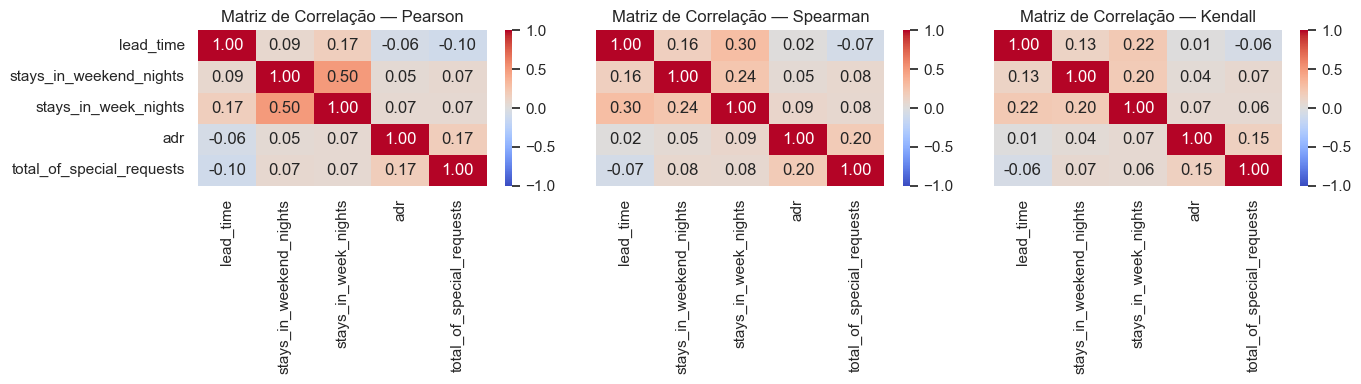

In [32]:
corr_pearson = df_tratado[VARS_QUANT].corr(method="pearson")
corr_spearman = df_tratado[VARS_QUANT].corr(method="spearman")
corr_kendall = df_tratado[VARS_QUANT].corr(method="kendall")

fig, ax = plt.subplots(1,3,figsize=(14, 4),sharey=True)
sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[0])
ax[0].set_title("Matriz de Correlação — Pearson")
sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[1])
ax[1].set_title("Matriz de Correlação — Spearman")
sns.heatmap(corr_kendall, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[2])
ax[2].set_title("Matriz de Correlação — Kendall")
plt.tight_layout()
plt.show()


**Leitura do gráfico:** cada matriz mostra a associação entre duas variáveis quantitativas. Valores próximos de `1` indicam associação positiva, valores próximos de `-1` indicam associação negativa e valores próximos de `0` indicam pouca associação.

Observei que a maior associação apareceu entre `stays_in_weekend_nights` e `stays_in_week_nights`. As demais relações foram fracas ou moderadas. A comparação entre os três métodos também mostrou que alguns coeficientes variaram conforme a forma de cálculo.

Em especial, Pearson mostrou uma associação mais alta entre as noites de fim de semana e as noites durante a semana. Uma possível explicação é que esse método usa os valores originais e pode ser mais influenciado por reservas com muitas noites. Já Spearman usa a ordem dos valores e lida de forma diferente com as várias repetições de valores baixos, comuns nessas variáveis de contagem.


Como os dados do triângulo superior e inferior são simétricos, poderíamos plotar a matriz de correlação da seguinte forma.

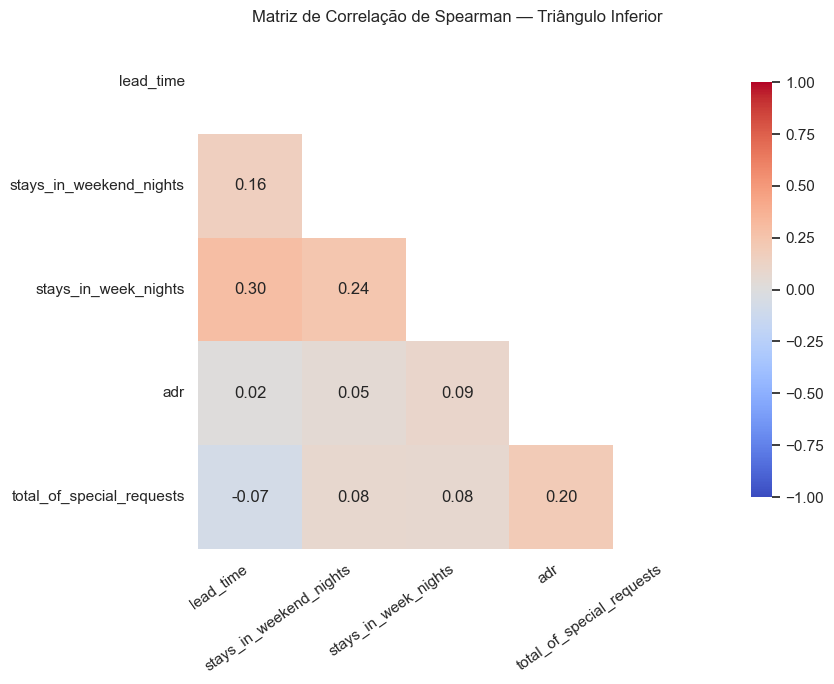

In [33]:
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))

plt.figure(figsize=(9, 7))
ax = sns.heatmap(
    corr_spearman, mask=mask, annot=True, cmap="coolwarm",
    fmt=".2f", square=True, vmin=-1, vmax=1,
    cbar_kws={"shrink": 0.8}
)

ax.set_title("Matriz de Correlação de Spearman — Triângulo Inferior")
ax.set_xticklabels(ax.get_xticklabels(), rotation=35, ha="right")
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
plt.grid(False)

plt.tight_layout()
plt.show()

**Pra discutir:** Pearson e Spearman divergem bastante em algum par de variáveis? Se sim, isso é um sinal de relação não-linear (monotônica, mas não em linha reta) em que Spearman capturaria e Pearson não.

*Resposta*: Sim. A diferença mais evidente apareceu entre `stays_in_weekend_nights` e `stays_in_week_nights`: Pearson mostrou `0,50`, enquanto Spearman mostrou `0,24`. Também houve diferença em `lead_time` e `stays_in_week_nights`, com `0,17` em Pearson e `0,30` em Spearman.

Uma possível explicação para a diferença é que Pearson pode ser mais influenciado por reservas com muitas noites, enquanto Spearman considera apenas a ordem dos valores e lida de outra forma com as repetições de valores baixos. Como as variáveis são assimétricas e de contagem, usei Spearman e Kendall como complementos, sem concluir apenas por essa diferença que existe uma relação não linear.


#### Dispersão (scatter) entre duas variáveis quantitativas

Escolhi `lead_time` x `adr` porque a antecedência e o preço médio diário são características importantes das reservas. Usei o gráfico para verificar se existia um padrão visual entre elas e como os dois status se distribuíam.

Mesmo que surgisse uma tendência, ela representaria uma associação observada na base, e não a prova de que uma variável causa a outra.

Reservas com ADR acima de 500: 3


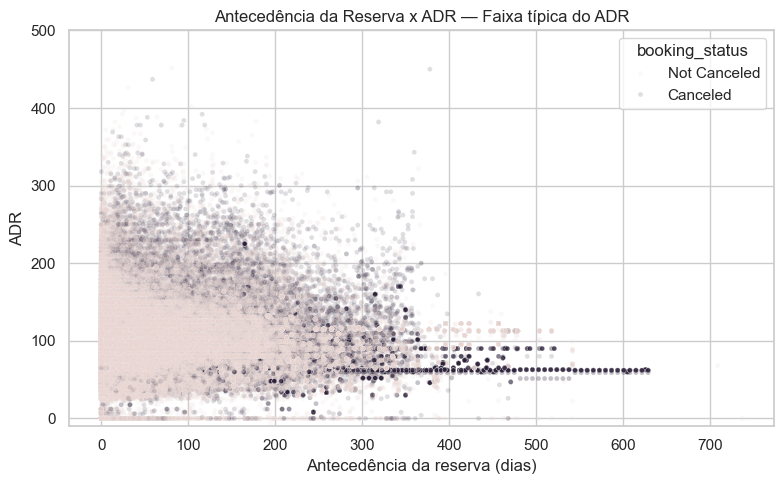

In [34]:
LIMITE_VISUAL_ADR = 500
reservas_fora_faixa = (df_tratado["adr"] > LIMITE_VISUAL_ADR).sum()
print(f"Reservas com ADR acima de {LIMITE_VISUAL_ADR}: {reservas_fora_faixa}")

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df_tratado,
    x="lead_time",
    y="adr",
    hue="booking_status",
    palette={"Not Canceled": COR_CONTEXTO, "Canceled": COR_DESTAQUE},
    alpha=0.15,
    s=12,
)
plt.title("Antecedência da Reserva x ADR — Faixa típica do ADR")
plt.xlabel("Antecedência da reserva (dias)")
plt.ylabel("ADR")
plt.ylim(-10, LIMITE_VISUAL_ADR)
plt.tight_layout()
plt.show()

**Leitura do gráfico:** cada ponto representa uma reserva. O eixo X mostra a antecedência da reserva e o eixo Y mostra o ADR; as cores distinguem reservas canceladas e não canceladas. A transparência reduz a sobreposição visual causada pela grande quantidade de reservas.

Para visualizar a concentração principal dos dados, limitei apenas a escala do gráfico a ADR de -10 até 500. O código informa quantas reservas ficaram fora dessa faixa visual; elas foram mantidas no dataset e já foram documentadas na etapa de outliers.

Observei uma nuvem de pontos bastante dispersa, sem uma tendência visual forte de aumento ou redução do ADR conforme a antecedência muda. Isso é coerente com a correlação de Spearman próxima de zero observada no bloco anterior.

**Pra discutir:** existe uma tendência visual entre `lead_time` e `adr`? Os dois status parecem ocupar regiões diferentes ou ficam bastante misturados? Responda apenas com base no padrão visível.

*Resposta*: Não observei uma tendência visual forte entre lead_time e ADR. As reservas aparecem distribuídas em diferentes faixas de antecedência e ADR, sem um padrão claro de que reservar mais perto da data resulte em diárias sempre maiores ou menores.

Os dois status ocupam regiões bastante misturadas no gráfico. Portanto, apenas com essa visualização, não foi possível diferenciar claramente reservas canceladas e não canceladas pelo conjunto formado por antecedência e ADR.


#### Quantitativa x Qualitativa: Comparando Grupos

Na aula foram apresentados **T-Test** para dois grupos e **ANOVA** para três ou mais grupos. Nesta base, usei o **Mann-Whitney U** como teste principal para dois grupos independentes, pois ele trabalha com postos e é mais adequado às distribuições assimétricas observadas.

Mantive o teste t de Welch como contraste pedagógico. Como a base é grande, interpretei os p-valores junto com as medianas e os gráficos, pois significância estatística não mede sozinha a importância prática da diferença.

In [35]:
def formatar_p_valor(p_valor):
    return "< 0,001" if p_valor < 0.001 else f"{p_valor:.3f}".replace(".", ",")

resultados_comparacao = []
for col in VARS_QUANT:
    grupo_nao_cancelado = df_tratado.loc[
        df_tratado["booking_status"] == "Not Canceled", col
    ]
    grupo_cancelado = df_tratado.loc[
        df_tratado["booking_status"] == "Canceled", col
    ]

    stat_t, p_t = stats.ttest_ind(
        grupo_nao_cancelado, grupo_cancelado, equal_var=False
    )
    stat_u, p_u = stats.mannwhitneyu(
        grupo_nao_cancelado, grupo_cancelado, alternative="two-sided"
    )

    resultados_comparacao.append({
        "variavel": col,
        "mediana_not_canceled": round(grupo_nao_cancelado.median(), 2),
        "mediana_canceled": round(grupo_cancelado.median(), 2),
        "p_valor_ttest_welch": formatar_p_valor(p_t),
        "p_valor_mannwhitney": formatar_p_valor(p_u),
        "concordam": (p_t < 0.05) == (p_u < 0.05),
    })

pd.DataFrame(resultados_comparacao).set_index("variavel")

,mediana_not_canceled,mediana_canceled,p_valor_ttest_welch,p_valor_mannwhitney,concordam
variavel,,,,,
lead_time,45.0,113.0,"< 0,001","< 0,001",True
stays_in_weekend_nights,1.0,1.0,"0,537","0,156",True
stays_in_week_nights,2.0,2.0,"< 0,001","< 0,001",True
adr,92.5,96.2,"< 0,001","< 0,001",True
total_of_special_requests,1.0,0.0,"< 0,001","< 0,001",True


**Leitura do resultado:** comparei as cinco variáveis entre reservas canceladas e não canceladas. Os p-valores inferiores a `0,001` foram apresentados dessa forma para evitar o falso valor `0.000e+00`.

Welch e Mann-Whitney concordaram em todas as variáveis. Pelo Mann-Whitney, encontrei evidência de diferença em `lead_time`, `stays_in_week_nights`, `adr` e `total_of_special_requests`. Entretanto, as medianas de noites em dias úteis foram iguais nos dois grupos, mostrando que um p-valor pequeno não implica necessariamente uma diferença prática grande.

**Pra discutir:** os dois testes concordam na maioria das variáveis? Como as distribuições são assimétricas, o **Mann-Whitney** deve ser tratado como resultado principal. Mesmo quando houver p-valor pequeno, a conclusão prática precisa ser complementada pelos gráficos e medidas descritivas.

*Resposta*: Sim. Os testes concordaram nas cinco variáveis. Pelo Mann-Whitney, apenas `stays_in_weekend_nights` não apresentou evidência suficiente de diferença entre os status. Nas demais, complementei os p-valores com as medianas, porque o teste não informa sozinho o tamanho nem a direção da diferença.

*Exemplo com 3+ grupos — ANOVA x Kruskal-Wallis*

Comparei o `adr` entre as categorias de `customer_type`. O Kruskal-Wallis informa se existe diferença em pelo menos um grupo, mas não identifica sozinho quais categorias diferem entre si.

ANOVA          — ADR entre categorias de customer_type: estatística=1302.356, p-valor=< 0,001
Kruskal-Wallis — ADR entre categorias de customer_type: estatística=4524.172, p-valor=< 0,001
Reservas com ADR acima de 500: 3


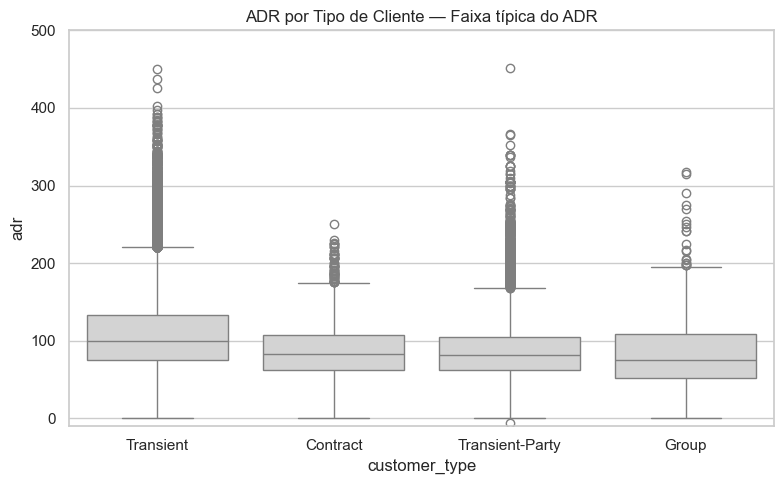

In [36]:
grupos_customer_type = [grupo["adr"].values for _, grupo in df_tratado.groupby("customer_type")]

stat_anova, p_anova = stats.f_oneway(*grupos_customer_type)
stat_kw, p_kw = stats.kruskal(*grupos_customer_type)

p_anova_texto = "< 0,001" if p_anova < 0.001 else f"{p_anova:.3f}"
p_kw_texto = "< 0,001" if p_kw < 0.001 else f"{p_kw:.3f}"

print(f"ANOVA          — ADR entre categorias de customer_type: estatística={stat_anova:.3f}, p-valor={p_anova_texto}")
print(f"Kruskal-Wallis — ADR entre categorias de customer_type: estatística={stat_kw:.3f}, p-valor={p_kw_texto}")

LIMITE_VISUAL_ADR = 500
reservas_fora_faixa = (df_tratado["adr"] > LIMITE_VISUAL_ADR).sum()
print(f"Reservas com ADR acima de {LIMITE_VISUAL_ADR}: {reservas_fora_faixa}")

plt.figure(figsize=(8, 5))
sns.boxplot(data=df_tratado, x="customer_type", y="adr", color=COR_NEUTRA)
plt.title("ADR por Tipo de Cliente — Faixa típica do ADR")
plt.ylim(-10, LIMITE_VISUAL_ADR)
plt.tight_layout()
plt.show()

**Leitura do gráfico:** cada caixa resume a distribuição de `adr` em uma categoria de `customer_type`. A linha central é a mediana, a caixa representa a região central dos dados e os pontos além dos limites indicam valores que se destacam segundo a regra do boxplot.

Para tornar visível a faixa principal de ADR, limitei apenas a escala do gráfico entre -10 e 500. O código mostra que três reservas ficaram fora dessa faixa visual; elas foram mantidas no dataset e já foram documentadas como valores extremos.

Observei que a categoria Transient apresentou a região central do ADR visualmente mais alta. Os outros tipos de cliente ficaram em faixas mais próximas entre si, embora o gráfico isolado não permita afirmar quais pares diferem de forma estatística.

**Pra discutir:** o Kruskal-Wallis concorda com a ANOVA sobre existir diferença entre pelo menos uma categoria de `customer_type`? O Kruskal-Wallis é o resultado principal; caso seja significativo, ele não informa sozinho quais pares de categorias diferem.

*Resposta*: Sim. ANOVA e Kruskal-Wallis indicaram diferença entre pelo menos um dos tipos de cliente. Como o ADR apresentou assimetria, considerei o Kruskal-Wallis como resultado principal.

O boxplot mostrou que Transient tende a apresentar ADR mais alto, mas os testes não identificam sozinhos quais pares de tipos de cliente diferem. Para essa conclusão, seria necessária uma análise posterior entre os pares de grupos.


#### Qualitativa x Qualitativa: Associação

booking_status,Canceled,Not Canceled
deposit_type,,
No Deposit,29694,74947
Non Refund,14494,93
Refundable,36,126


Menor frequência esperada: 60.01
p-valor do Qui-Quadrado: < 0,001


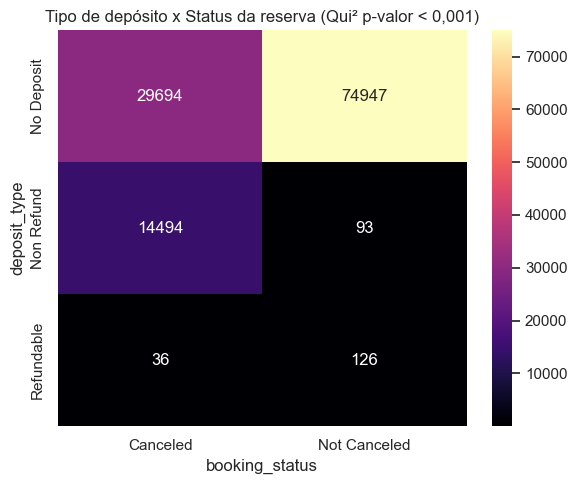

In [37]:
contingencia_deposito = pd.crosstab(df_tratado["deposit_type"], df_tratado["booking_status"])
chi2, p_chi2, gl, esperado = stats.chi2_contingency(contingencia_deposito)

display(contingencia_deposito)

p_chi2_texto = "< 0,001" if p_chi2 < 0.001 else f"= {p_chi2:.3f}"
print(f"Menor frequência esperada: {esperado.min():.2f}")
print(f"p-valor do Qui-Quadrado: {p_chi2_texto}")

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(contingencia_deposito, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title(f"Tipo de depósito x Status da reserva (Qui² p-valor {p_chi2_texto})")
plt.tight_layout()
plt.show()

**Leitura do gráfico:** a tabela e o heatmap mostram a quantidade de reservas em cada combinação entre `deposit_type` e `booking_status`. No heatmap, as linhas representam os tipos de depósito, as colunas representam os status da reserva e as cores mais claras indicam quantidades maiores.

Observei que `No Deposit` concentra muitas reservas nos dois status, pois é a categoria mais frequente na base. Já em `Non Refund`, a maior parte das reservas aparece na coluna `Canceled`. A tabela mostra quantidades absolutas; por isso, ela ainda não permite comparar diretamente a proporção de cancelamentos de cada tipo de depósito.


**Pra discutir:** o p-valor do Qui-Quadrado sugere independência ou associação entre `deposit_type` e `booking_status`? Antes de interpretar, verifique se a menor frequência esperada é adequada. O teste mostra associação, não explica a causa dela.

*Resposta*: A menor frequência esperada foi `60,01`, valor acima de 5; assim, a condição usual para interpretar o teste de Qui-Quadrado foi atendida. Como o p-valor foi menor que `0,001`, rejeitei a hipótese de independência e identifiquei evidência de associação entre `deposit_type` e `booking_status`.

O resultado não mostra a causa dessa associação. Ele apenas indica que a distribuição entre reservas canceladas e não canceladas varia conforme o tipo de depósito.


#### Padrões de cancelamento por segmento

Como o dataset não possui atributos como sexo ou idade, não mantive o título de fairness usado no exemplo médico. Observei, em vez disso, as proporções de cancelamento por tipo de hotel e tipo de cliente. Esses padrões descrevem as reservas da base e não demonstram a causa do cancelamento.

In [38]:
metricas_segmento = pd.DataFrame({
    "hotel": metrica_desbalanceamento(df_tratado["hotel"]),
    "customer_type": metrica_desbalanceamento(df_tratado["customer_type"])
}).T

display(metricas_segmento.round(3))

,n_classes,razao_desbalanceamento,entropia_normalizada
hotel,2.0,1.98,0.920
customer_type,4.0,155.31,0.494


**Leitura do resultado:** a tabela confirma que os dois tipos de hotel possuem tamanhos relativamente próximos, com razão de desbalanceamento de `1,98` e entropia normalizada de `0,920`. Já `customer_type` é mais desbalanceada, com razão de `155,31` e entropia de `0,494`, pois algumas categorias possuem bem menos reservas que outras.

Por isso, usei proporções de cancelamento no gráfico seguinte. Dessa forma, a comparação não fica dependente apenas do tamanho de cada grupo.


booking_status,Canceled,Not Canceled
hotel,,
City Hotel,0.417,0.583
Resort Hotel,0.278,0.722


booking_status,Canceled,Not Canceled
customer_type,,
Contract,0.310,0.690
Group,0.102,0.898
Transient,0.407,0.593
Transient-Party,0.254,0.746


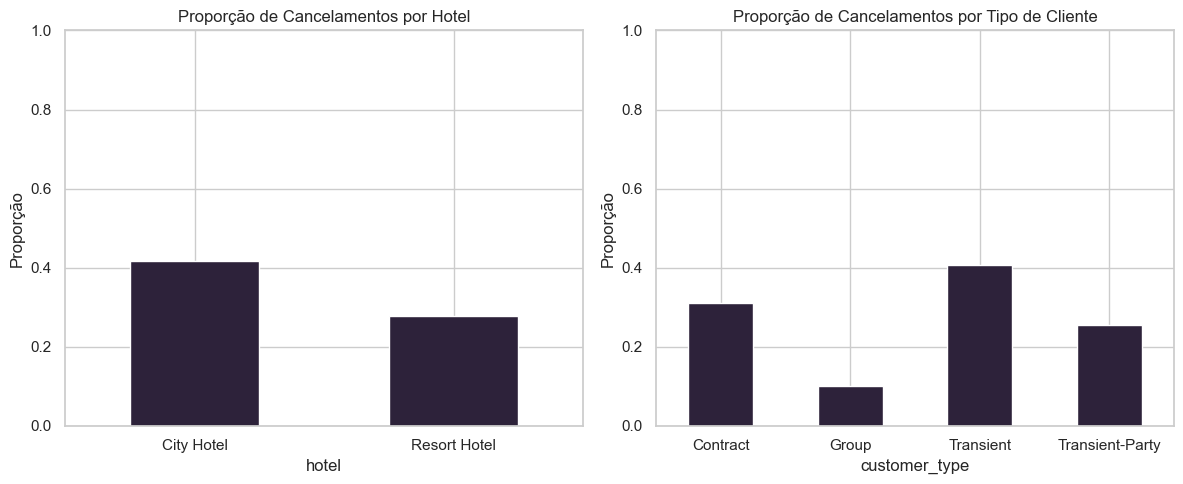

In [39]:
prop_por_hotel = pd.crosstab(df_tratado["hotel"], df_tratado["booking_status"], normalize="index").round(3)
prop_por_customer_type = pd.crosstab(df_tratado["customer_type"], df_tratado["booking_status"], normalize="index").round(3)

display(prop_por_hotel)
display(prop_por_customer_type)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

prop_por_hotel["Canceled"].plot(kind="bar", color=COR_DESTAQUE, ax=axes[0])
axes[0].set_title("Proporção de Cancelamentos por Hotel")
axes[0].set_ylabel("Proporção")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=0)

prop_por_customer_type["Canceled"].plot(kind="bar", color=COR_DESTAQUE, ax=axes[1])
axes[1].set_title("Proporção de Cancelamentos por Tipo de Cliente")
axes[1].set_ylabel("Proporção")
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

**Leitura do gráfico:** cada barra e cada valor nas tabelas mostram a proporção de reservas canceladas dentro da categoria indicada, e não o número absoluto de reservas. Assim, o eixo Y representa uma proporção entre 0 e 1, permitindo comparar grupos com quantidades diferentes de reservas.

Observei uma proporção maior de cancelamentos no `City Hotel` (`0,417`) do que no `Resort Hotel` (`0,278`). Entre os tipos de cliente, `Transient` apresentou a maior proporção (`0,407`), enquanto `Group` apresentou a menor (`0,102`).


**Pra discutir:** a proporção de cancelamentos parece variar entre os tipos de hotel ou entre os tipos de cliente? Descreva somente o padrão observado, sem atribuir uma causa ao resultado.

*Resposta*: Sim. A proporção de cancelamentos variou entre os dois tipos de hotel e também entre os tipos de cliente. O `City Hotel` apresentou uma proporção maior que o `Resort Hotel`. Entre os tipos de cliente, `Transient` ficou com a maior proporção, enquanto `Group` ficou com a menor.

Esses resultados descrevem os padrões observados nas reservas da base. Eles não permitem concluir por que essas diferenças ocorreram.


--- hotel ---


booking_status,Canceled,Not Canceled
hotel,,
City Hotel,33102,46228
Resort Hotel,11122,28938


Menor frequência esperada: 14838.88
p-valor do Qui-Quadrado: < 0,001


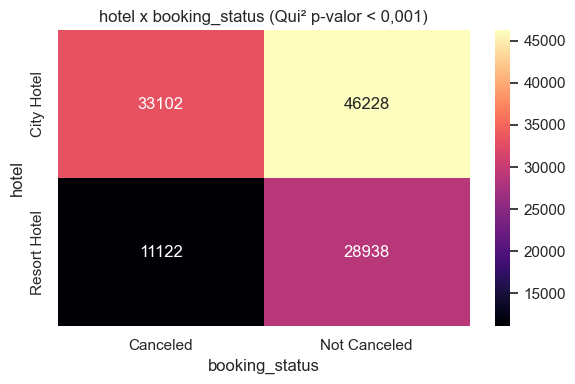

--- customer_type ---


booking_status,Canceled,Not Canceled
customer_type,,
Contract,1262,2814
Group,59,518
Transient,36514,53099
Transient-Party,6389,18735


Menor frequência esperada: 213.73
p-valor do Qui-Quadrado: < 0,001


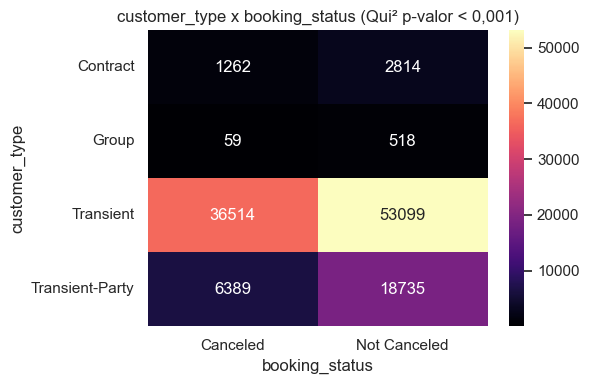

In [40]:
for atributo in ["hotel", "customer_type"]:
    contingencia = pd.crosstab(df_tratado[atributo], df_tratado["booking_status"])
    chi2, p_valor, gl, esperado = stats.chi2_contingency(contingencia)
    p_valor_texto = "< 0,001" if p_valor < 0.001 else f"= {p_valor:.3f}"

    print(f"--- {atributo} ---")
    display(contingencia)
    print(f"Menor frequência esperada: {esperado.min():.2f}")
    print(f"p-valor do Qui-Quadrado: {p_valor_texto}")

    fig, ax = plt.subplots(figsize=(6, 4))
    sns.heatmap(contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
    ax.set_title(f"{atributo} x booking_status (Qui² p-valor {p_valor_texto})")
    plt.tight_layout()
    plt.show()

**Leitura do resultado:** em cada tabela, as linhas representam as categorias de `hotel` ou `customer_type`, e as colunas mostram as quantidades de reservas `Canceled` e `Not Canceled`. Os heatmaps representam esses mesmos valores por intensidade de cor.

Observei que as menores frequências esperadas informadas pelo código são adequadas para os dois testes. Os p-valores menores que `0,001` indicam evidência de associação entre cada uma dessas variáveis e o status da reserva.


**Pra discutir:** o Qui-Quadrado sugere associação entre `hotel` ou `customer_type` e o status da reserva? Verifique primeiro as frequências esperadas exibidas pelo código. Mesmo que exista significância estatística, o teste não mostra por que a associação ocorre.

*Resposta*: Sim. Como as frequências esperadas foram adequadas e os dois p-valores foram menores que `0,001`, identifiquei evidência de associação entre `hotel` e `booking_status`, bem como entre `customer_type` e `booking_status`.

Essa conclusão confirma que as proporções visualizadas no bloco anterior variam entre as categorias. No entanto, o teste não mostra a causa dessas diferenças.


#### Outliers bivariados

Escolhi `lead_time` e `stays_in_week_nights` porque esse foi o par com a maior correlação de Spearman entre as quantitativas analisadas. O `jointplot` permitiu observar simultaneamente a relação entre as duas variáveis e suas distribuições marginais.

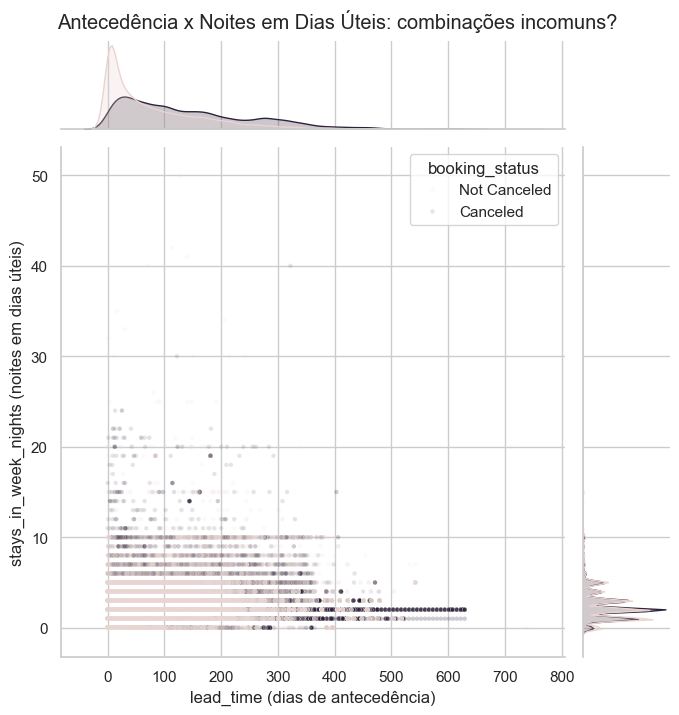

In [41]:
g = sns.jointplot(
    data=df_tratado,
    x="lead_time",
    y="stays_in_week_nights",
    hue="booking_status",
    palette={"Not Canceled": COR_CONTEXTO, "Canceled": COR_DESTAQUE},
    alpha=0.12,
    s=10,
    height=7,
    marginal_kws={"common_norm": False},
)

g.set_axis_labels(
    "lead_time (dias de antecedência)",
    "stays_in_week_nights (noites em dias úteis)"
)
g.fig.suptitle(
    "Antecedência x Noites em Dias Úteis: combinações incomuns?",
    y=1.02
)
plt.show()

**Leitura do gráfico:** o painel central relaciona os dias de antecedência com as noites em dias úteis; os painéis marginais mostram a distribuição de cada variável separadamente. Cada ponto representa uma reserva e as cores distinguem os dois status.

Observei grande concentração em estadias curtas e uma faixa ampla de antecedência. Alguns pontos ficaram isolados em estadias muito longas, mas eles também já se destacavam na análise univariada da quantidade de noites.

**Pra discutir:** existe algum ponto que não parecia outlier nos histogramas univariados, mas que se destaca aqui como uma combinação incomum de `lead_time` e `stays_in_week_nights`?

*Resposta*: Não identifiquei com clareza um caso que fosse comum nas duas análises univariadas e se tornasse extremo apenas pela combinação. Os pontos mais isolados envolveram estadias longas, que já apareciam como valores incomuns individualmente. Por isso, não removi nenhuma reserva com base apenas neste gráfico.

#### Análise Multivariada

##### Matriz de Correlação

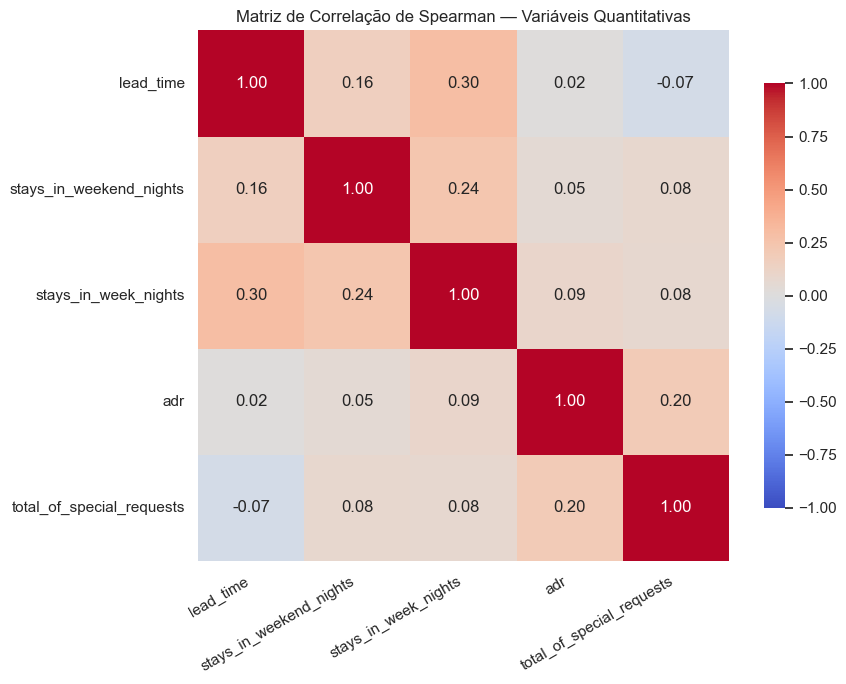

In [42]:
corr_spearman = df_tratado[VARS_QUANT].corr(method="spearman")

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(
    corr_spearman,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    square=True,
    cbar_kws={"shrink": 0.8},
    ax=ax,
)
ax.set_title("Matriz de Correlação de Spearman — Variáveis Quantitativas")
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha="right")
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
plt.tight_layout()
plt.show()


**Leitura do gráfico:** cada célula compara duas variáveis quantitativas, e a cor representa o coeficiente de correlação de Spearman. Valores positivos indicam que as variáveis tendem a crescer na mesma direção; valores negativos indicam sentidos opostos. A diagonal é igual a 1 porque cada variável é comparada com ela mesma.

Observei que a maior correlação fora da diagonal foi entre `lead_time` e `stays_in_week_nights` (`0,30`). As demais correlações foram fracas ou muito próximas de zero, como `lead_time` e `adr` (`0,02`).


**Como interpretar:**


*   |r| < 0.3 ~ fraca,
*   0.3 < |r| < 0.7 ~ moderada,
*  |r| > 0.7 ~ forte.

Alguma correlação chama atenção por ser forte o suficiente pra sugerir redundância entre variáveis?

*Resposta*: Não. Nenhuma correlação fora da diagonal se aproximou de `0,7` em módulo, que seria um indício de relação forte. A maior foi `0,30`, entre `lead_time` e `stays_in_week_nights`; portanto, não identifiquei redundância forte entre as variáveis quantitativas analisadas.


##### Correlograma

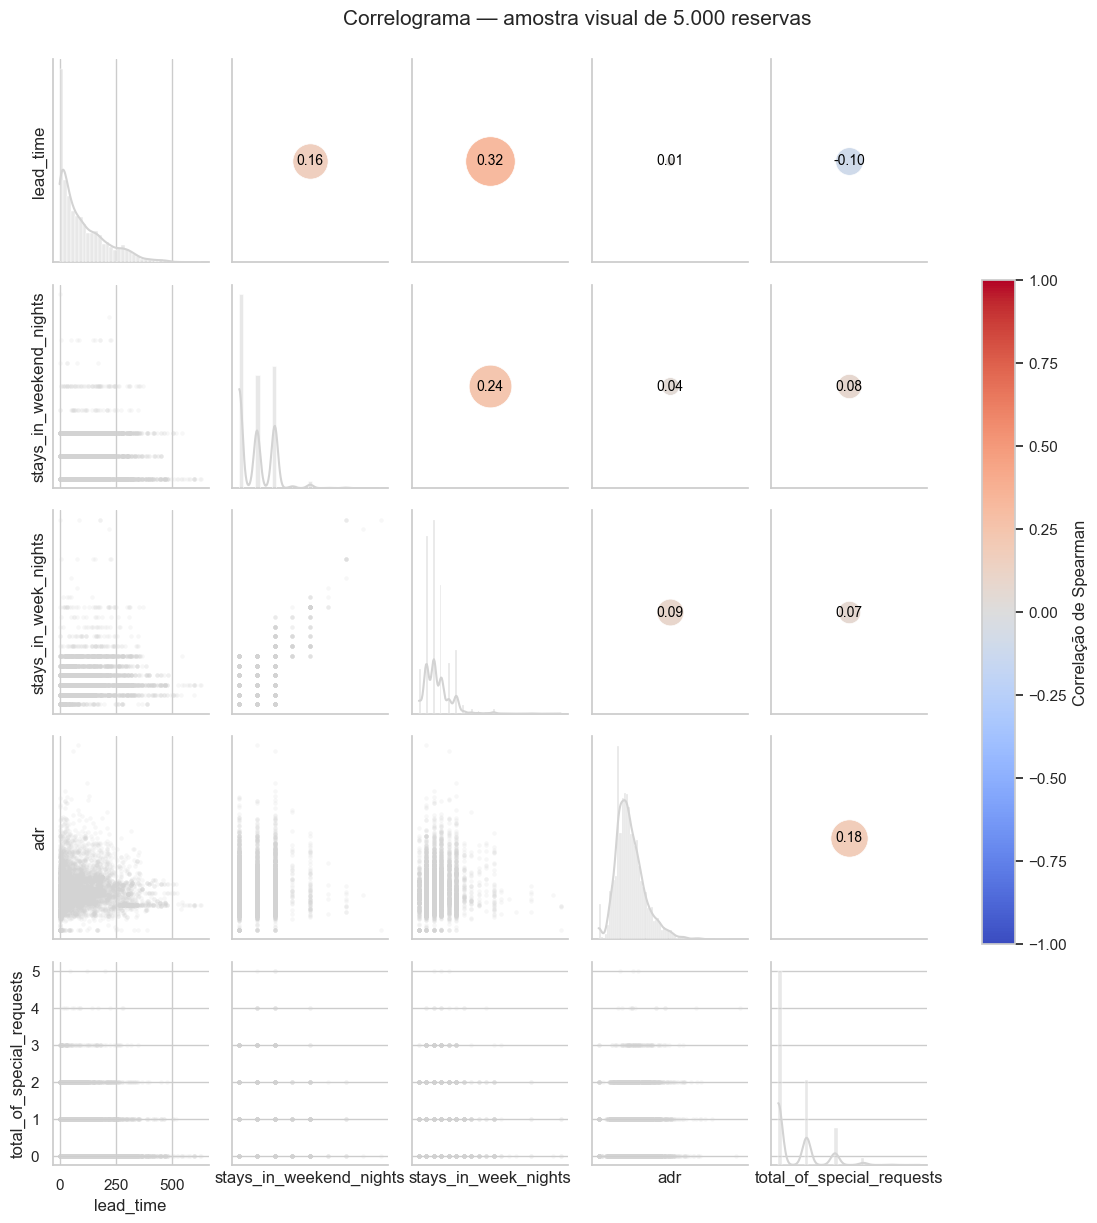

In [43]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

TAMANHO_AMOSTRA_CORRELOGRAMA = 5000
amostra_correlograma = df_tratado[VARS_QUANT].sample(
    n=TAMANHO_AMOSTRA_CORRELOGRAMA,
    random_state=42
)

def circulo_correlacao(x, y, **kwargs):
    r = stats.spearmanr(x, y).statistic
    ax = plt.gca()
    ax.scatter(
        [0.5], [0.5],
        s=abs(r) * 4000,
        c=[r], cmap="coolwarm", vmin=-1, vmax=1,
        transform=ax.transAxes, edgecolor="white", linewidth=0.5,
    )
    ax.annotate(
        f"{r:.2f}", xy=(0.5, 0.5), xycoords=ax.transAxes,
        ha="center", va="center", fontsize=10,
        color="white" if abs(r) > 0.5 else "black"
    )
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)

g = sns.PairGrid(amostra_correlograma, diag_sharey=False, height=2.4)
g.map_lower(sns.scatterplot, color=COR_NEUTRA, alpha=0.18, s=10, linewidth=0)
g.map_diag(sns.histplot, color=COR_NEUTRA, kde=True)
g.map_upper(circulo_correlacao)

sm = ScalarMappable(norm=Normalize(-1, 1), cmap="coolwarm")
sm.set_array([])
g.fig.colorbar(sm, ax=g.axes, shrink=0.6, label="Correlação de Spearman")

g.fig.suptitle(
    "Correlograma — amostra visual de 5.000 reservas",
    y=1.02,
    fontsize=15
)
plt.show()

**Leitura do gráfico:** na diagonal, observei a distribuição de cada variável; abaixo dela, os gráficos de dispersão mostraram as relações par a par; acima, o tamanho e a cor dos círculos representaram a correlação de Spearman.

Usei uma amostra fixa de 5.000 reservas apenas para tornar os pontos legíveis. A matriz anterior, calculada com a base completa, permaneceu como referência numérica principal. O correlograma reforçou a ausência de relações fortes entre as cinco variáveis.

## Principais conclusões

- Identifiquei distribuições assimétricas e não normais nas cinco variáveis quantitativas, com valores extremos especialmente visíveis em `adr`.
- `lead_time` apresentou a diferença visual mais clara entre reservas canceladas e não canceladas.
- Tratei os campos ausentes sem excluir reservas e mantive os candidatos a outlier por falta de evidência de erro.
- As correlações entre as quantitativas foram fracas ou moderadas, sem indício de redundância forte; `lead_time` e `adr` também não mostraram uma tendência visual clara.
- Encontrei associação entre o status da reserva e características como tipo de depósito, hotel e tipo de cliente, sem interpretar essas associações como causalidade.

## Declaração de Uso de IA

Utilizei o Codex, da OpenAI, para apoiar a adaptação e revisão do código, das visualizações e das interpretações do notebook. Conferi as sugestões com os resultados exibidos: aceitei ou ajustei as que preservavam a estrutura da atividade e eram coerentes com os dados, e rejeitei as que acrescentariam complexidade desnecessária ou conclusões sem evidência.